# Contact distance analysis

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Protein DBD with DNA

### Load data

In [4]:
wt_dbd_dfs = []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/004.contacts/pairs_dbd.csv')
    wt_dbd_dfs.append(df)

T419R_dbd_dfs = []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/T419R/rep{rep}/analysis/004.contacts/pairs_dbd.csv')
    T419R_dbd_dfs.append(df)

In [5]:
wt_dbd_dfs[0].head()

,frame,sele1_resid,sele1_resnm,sele1_chain,sele2_resid,sele2_resnm,sele2_chain,distance
0,1000,190,MET,A,12,DG,D,4.907506
1,1000,190,MET,A,12,DG,D,4.486903
2,1000,192,THR,A,12,DG,D,4.632156
3,1000,192,THR,A,11,DC,D,4.287577
4,1000,192,THR,A,11,DC,D,4.939452


### Preprocessing

Adjust residue numbers.

In [6]:
def adjust_resid(dfs):
    for df in (dfs):
        df["sele1_resid_adj"] = np.where(
            df["sele1_resnm"].str.match(r'^[A-Za-z]{3}$'),
            df["sele1_resid"] + 135,
            df["sele1_resid"]
        )
        df["sele2_resid_adj"] = np.where(
            df["sele2_resnm"].str.match(r'^[A-Za-z]{3}$'),
            df["sele2_resid"] + 135,
            df["sele2_resid"]
    )

In [7]:
adjust_resid(wt_dbd_dfs + T419R_dbd_dfs)

In [8]:
wt_dbd_dfs[0].head()

,frame,sele1_resid,sele1_resnm,sele1_chain,sele2_resid,sele2_resnm,sele2_chain,distance,sele1_resid_adj,sele2_resid_adj
0,1000,190,MET,A,12,DG,D,4.907506,325,12
1,1000,190,MET,A,12,DG,D,4.486903,325,12
2,1000,192,THR,A,12,DG,D,4.632156,327,12
3,1000,192,THR,A,11,DC,D,4.287577,327,11
4,1000,192,THR,A,11,DC,D,4.939452,327,11


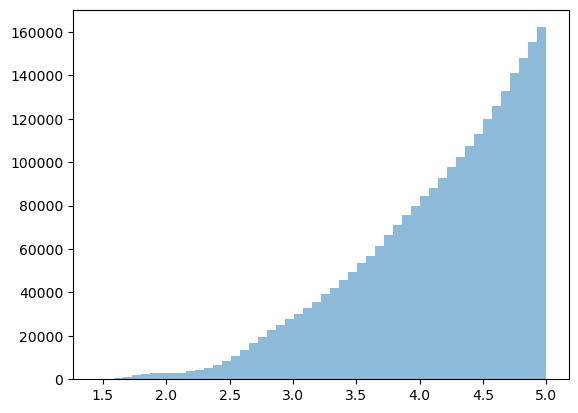

In [9]:
plt.hist(wt_dbd_dfs[0]['distance'], bins=50, alpha=0.5, label='wt', )
plt.show()

Note that each contact is associated with two residues, but no specific atoms. For this reason, a residue pair might be present multiple times in a single frame and, as seen next, dividing the count of a pair by the total number of frames might result in a value higher than 100. 

In [ ]:
def aggregate_pairs(df_list):
    combined = pd.concat(df_list)
    
    agg_df = combined.groupby(['sele1_resnm', 'sele1_resid_adj', 'sele1_chain', 
                              'sele2_resnm', 'sele2_resid_adj', 'sele2_chain']).agg(
        count=('distance', 'size'), 
        distance_avg=('distance', 'mean') 
    ).reset_index()
    
    return agg_df

In [117]:
wt_dbd_agg = aggregate_pairs(wt_dbd_dfs)
T419R_dbd_agg = aggregate_pairs(T419R_dbd_dfs)

In [119]:
wt_dbd_agg.sort_values('distance_avg', ascending=True).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg
181,GLY,422,B,DT,7,D,21063,3.887578
376,THR,419,B,DT,8,D,24459,3.906081
80,ASN,460,B,DA,15,C,54834,3.961775
356,THR,417,B,DA,21,C,6766,3.967327
94,GLN,340,A,DC,11,D,29475,4.011293
11,ARG,378,A,DT,8,C,101445,4.012405
173,GLY,422,A,DG,6,C,91321,4.017636
371,THR,419,B,DA,21,C,24643,4.024574
99,GLN,340,B,DC,11,C,83039,4.027218
120,GLN,463,B,DT,8,D,85619,4.036318


In [120]:
wt_dbd_agg["count_avg"] = wt_dbd_agg["count"] / (len(wt_dbd_dfs)* 1000)
T419R_dbd_agg["count_avg"] = T419R_dbd_agg["count"] / (len(T419R_dbd_dfs)* 1000)

In [121]:
wt_dbd_agg.sort_values('count_avg', ascending=False).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg,count_avg
36,ARG,418,B,DG,19,C,283033,4.145784,94.344333
302,SER,459,A,DT,8,C,278783,4.098669,92.927667
38,ARG,418,B,DT,7,D,257178,4.160853,85.726000
114,GLN,463,A,DT,7,C,202698,4.101309,67.566000
391,VAL,339,B,DC,11,C,178984,4.136174,59.661333
337,THR,327,A,DC,11,D,168211,4.138601,56.070333
34,ARG,418,B,DC,20,C,167178,4.146232,55.726000
26,ARG,418,A,DG,20,D,159261,4.104046,53.087000
415,VAL,461,B,DG,13,C,142352,4.174150,47.450667
89,ASN,460,B,DT,8,D,125384,4.173410,41.794667


In [122]:
T419R_dbd_agg.sort_values('count_avg', ascending=False).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg,count_avg
50,ARG,419,A,DG,20,D,375678,4.113897,125.226000
61,ARG,419,B,DG,19,C,322140,4.185668,107.380000
365,VAL,339,B,DC,11,C,317278,4.126990,105.759333
305,SER,459,B,DT,8,D,256219,4.106231,85.406333
36,ARG,418,B,DC,20,C,243926,4.122768,81.308667
49,ARG,419,A,DG,6,C,217687,4.179055,72.562333
287,PRO,423,A,DG,6,C,211016,4.152988,70.338667
62,ARG,419,B,DT,7,D,207056,4.236805,69.018667
63,ARG,419,B,DT,8,D,190097,4.149556,63.365667
128,GLN,463,B,DT,7,D,167593,4.124034,55.864333


### Comparison

In [ ]:
def pivotdf_count_avg(df):
    pivot = df.pivot_table(values='count_avg', 
                          index='sele2_resid_adj', 
                          columns='sele1_resid_adj', 
                          aggfunc='mean')
    return pivot

In [ ]:
wt_dbd_pivot = pivotdf_count_avg(wt_dbd_agg)
mut_dbd_pivot = pivotdf_count_avg(T419R_dbd_agg)

In [125]:
wt_dbd_pivot.head()

sele1_resid_adj,325,326,327,328,329,330,331,336,337,338,...,429,457,458,459,460,461,462,463,464,466
sele2_resid_adj,,,,,,,,,,,,,,,,,,,,,
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.002667,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.0005,NaN,0.033167,1.773167,NaN,0.0015


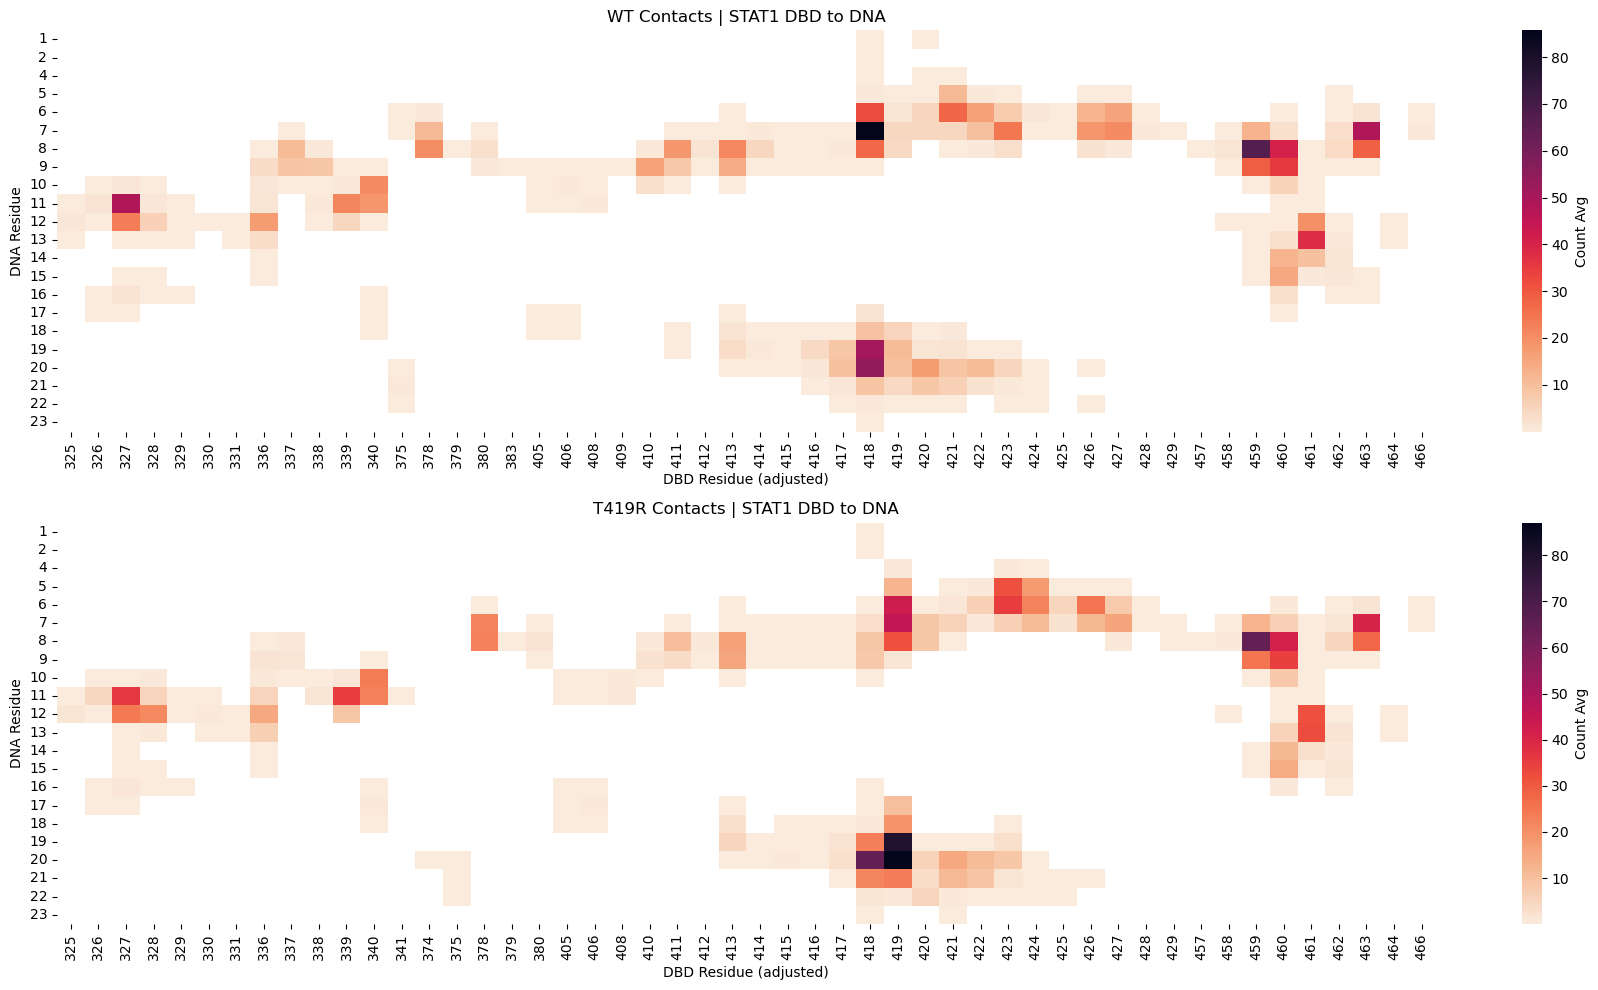

In [126]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), sharey=True)

# WT heatmap
sns.heatmap(wt_dbd_pivot, cmap='rocket_r', ax=ax1, cbar_kws={'label': 'Count Avg'})
ax1.set_title('WT Contacts | STAT1 DBD to DNA')
ax1.set_xlabel('DBD Residue (adjusted)')
ax1.set_ylabel('DNA Residue')

# T419R heatmap
sns.heatmap(mut_dbd_pivot, cmap='rocket_r', ax=ax2, cbar_kws={'label': 'Count Avg'})
ax2.set_title('T419R Contacts | STAT1 DBD to DNA')
ax2.set_xlabel('DBD Residue (adjusted)')
ax2.set_ylabel('DNA Residue')

plt.tight_layout()
plt.show()

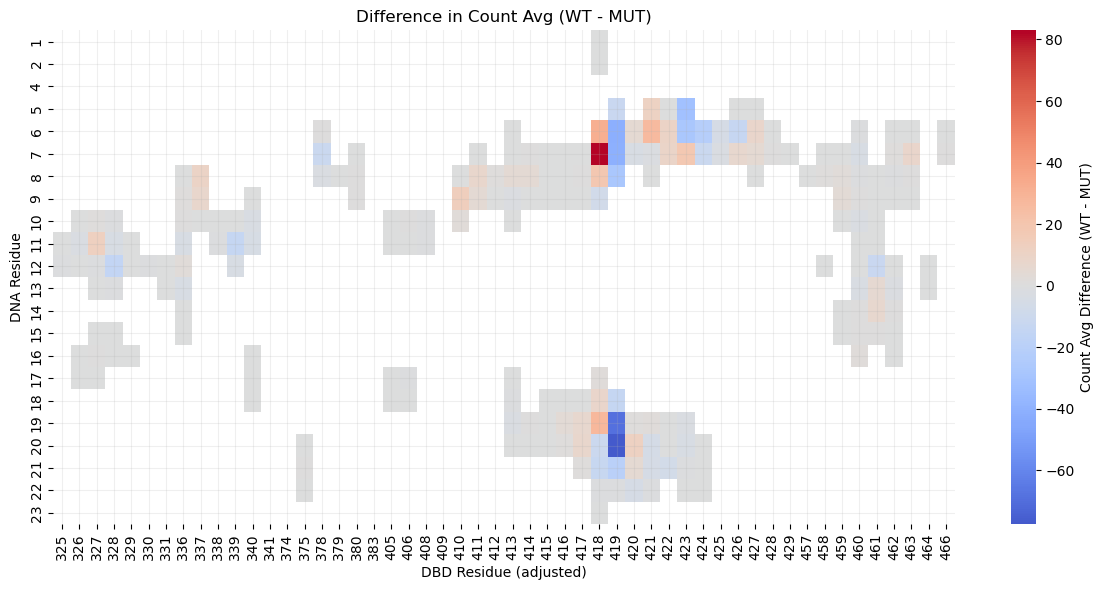

In [127]:
diff_dbd_pivot = wt_dbd_pivot - mut_dbd_pivot

plt.figure(figsize=(12, 6))

sns.heatmap(diff_dbd_pivot, cmap='coolwarm', center=0, cbar_kws={'label': 'Count Avg Difference (WT - MUT)'})
plt.title('Difference in Count Avg (WT - MUT)')
plt.xlabel('DBD Residue (adjusted)')
plt.ylabel('DNA Residue')

plt.grid(alpha = 0.2)
plt.tight_layout()
plt.show()

#### By monomer

In [128]:
wt_dbd_agg['sele1_chain'].value_counts()

sele1_chain
A    210
B    209
Name: count, dtype: int64

In [129]:
wt_dbd_agg_monoA = wt_dbd_agg[wt_dbd_agg['sele1_chain'] == 'A']
wt_dbd_agg_monoB = wt_dbd_agg[wt_dbd_agg['sele1_chain'] == 'B']

In [130]:
T419R_dbd_agg['sele1_chain'].value_counts()

sele1_chain
A    202
B    193
Name: count, dtype: int64

In [131]:
T419R_dbd_agg_monoA = T419R_dbd_agg[T419R_dbd_agg['sele1_chain'] == 'A']
T419R_dbd_agg_monoB = T419R_dbd_agg[T419R_dbd_agg['sele1_chain'] == 'B']

In [ ]:
wt_dbd_monoA_pivot = pivotdf_count_avg(wt_dbd_agg_monoA)
wt_dbd_monoB_pivot = pivotdf_count_avg(wt_dbd_agg_monoB)
mut_dbd_monoA_pivot = pivotdf_count_avg(T419R_dbd_agg_monoA)
mut_dbd_monoB_pivot = pivotdf_count_avg(T419R_dbd_agg_monoB)

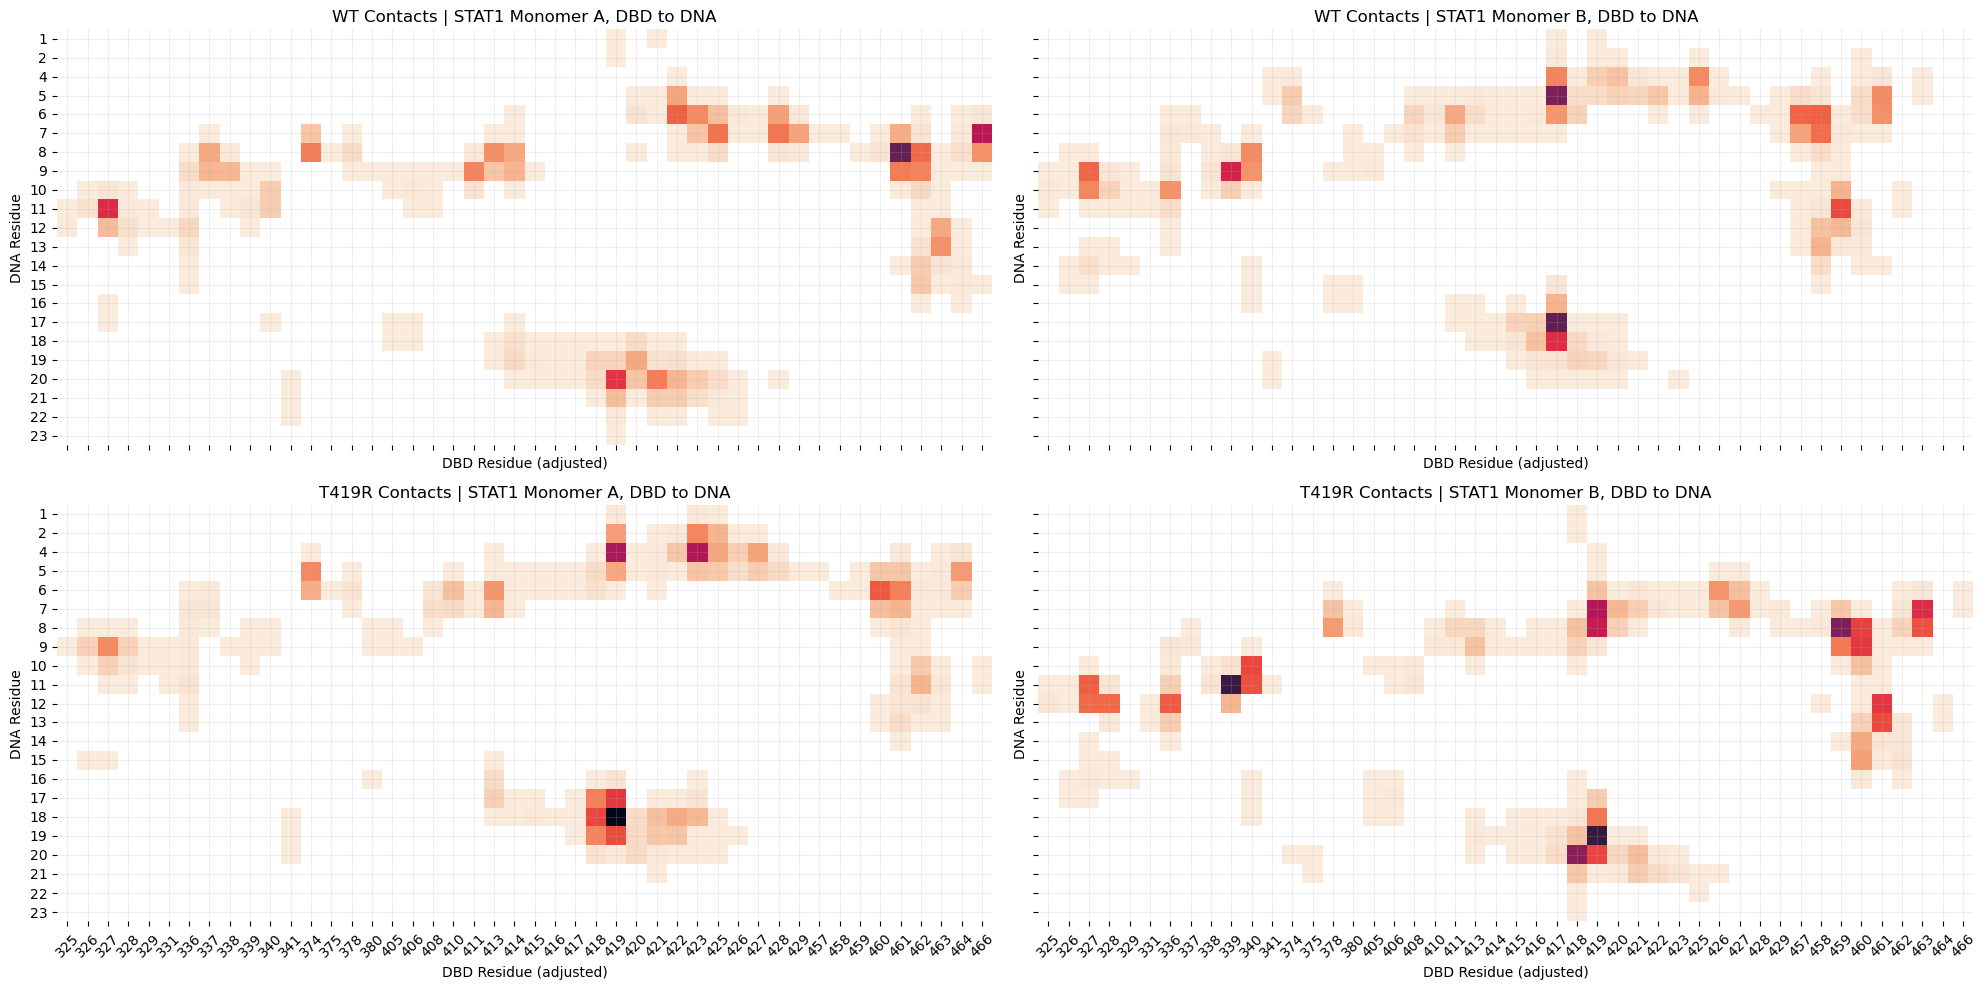

In [133]:
# Find global min and max
all_data = [
    wt_dbd_monoA_pivot.values,
    wt_dbd_monoB_pivot.values,
    mut_dbd_monoA_pivot.values,
    mut_dbd_monoB_pivot.values
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(20, 10), sharey=True, sharex=True)
ax1, ax2, ax3, ax4 = axes.flatten()
plots = [
    (wt_dbd_monoA_pivot, ax1, 'WT Contacts | STAT1 Monomer A, DBD to DNA'),
    (wt_dbd_monoB_pivot, ax2, 'WT Contacts | STAT1 Monomer B, DBD to DNA'),
    (mut_dbd_monoA_pivot, ax3, 'T419R Contacts | STAT1 Monomer A, DBD to DNA'),
    (mut_dbd_monoB_pivot, ax4, 'T419R Contacts | STAT1 Monomer B, DBD to DNA')
]

for pivot_df, ax, title in plots:
    sns.heatmap(
        pivot_df, 
        cmap='rocket_r', 
        ax=ax, 
        cbar=False, 
        vmin=global_min, 
        vmax=global_max
    )
    ax.set_title(title)
    ax.set_xlabel('DBD Residue (adjusted)')
    ax.set_ylabel('DNA Residue')
    ax.grid(alpha=0.2)

# Rotate x-axis labels for all axes
for ax in axes.flatten():
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

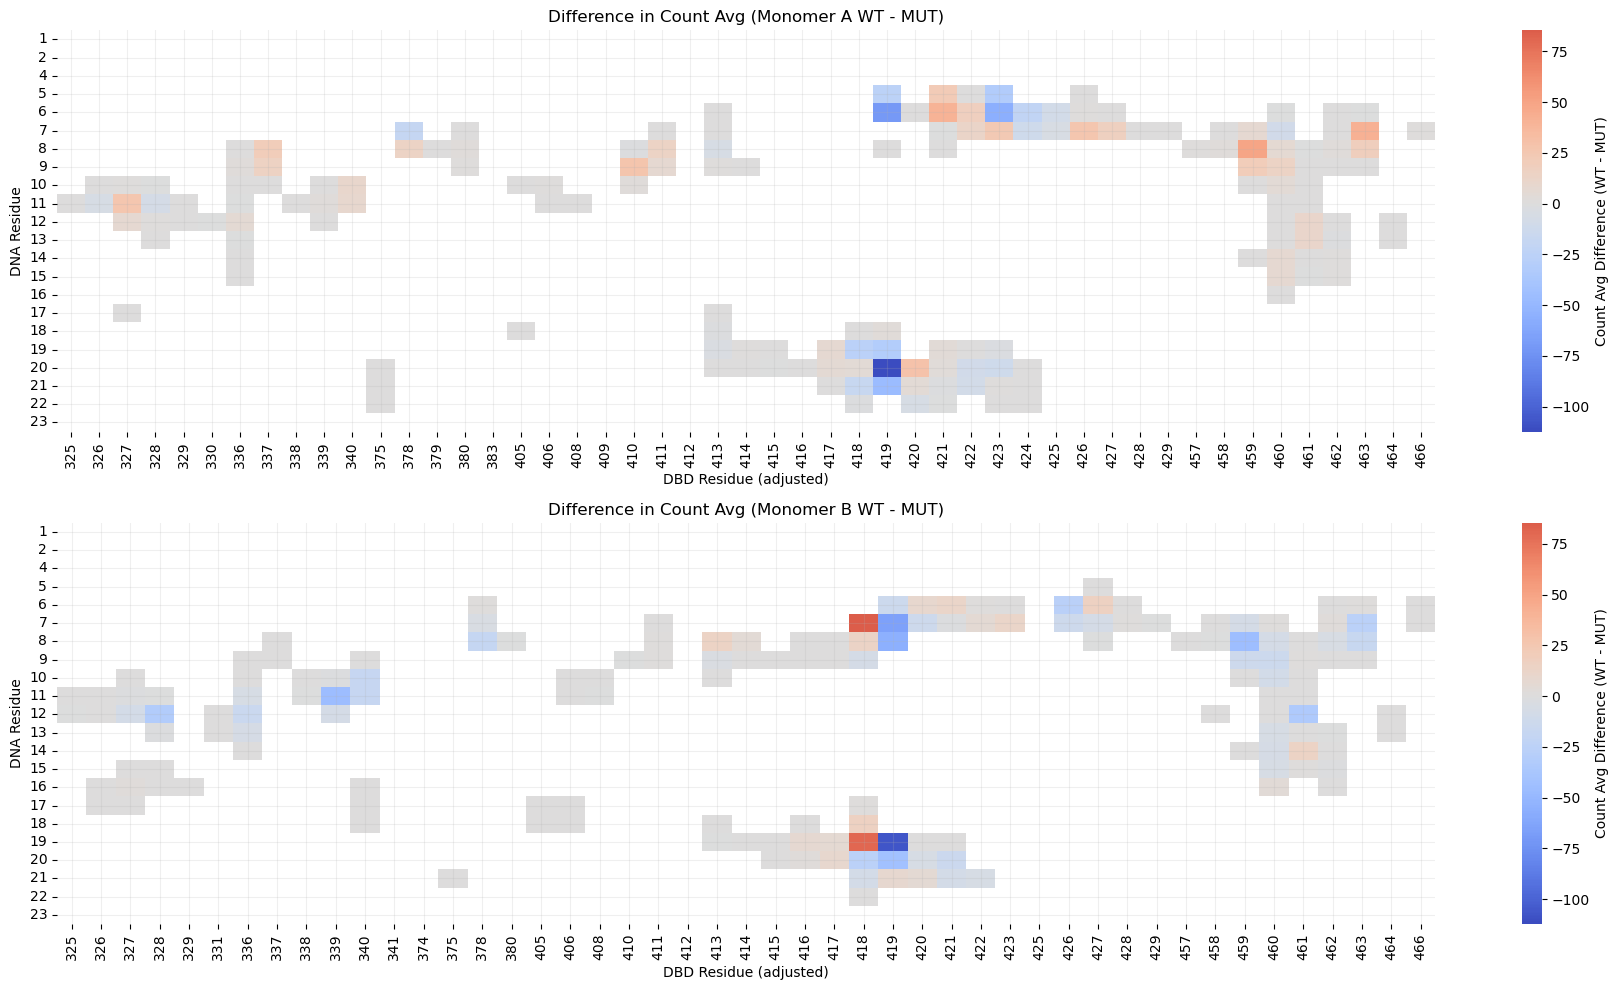

In [134]:
diff_dbd_monoA_pivot = wt_dbd_monoA_pivot - mut_dbd_monoA_pivot
diff_dbd_monoB_pivot = wt_dbd_monoB_pivot - mut_dbd_monoB_pivot

# Find global min and max
all_data = [
    diff_dbd_monoA_pivot.values,
    diff_dbd_monoB_pivot.values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), sharey=True)

# Monomer A
sns.heatmap(diff_dbd_monoA_pivot, cmap='coolwarm', center=0, ax=ax1, vmin=global_min, vmax=global_max, cbar_kws={'label': 'Count Avg Difference (WT - MUT)'})
ax1.set_title('Difference in Count Avg (Monomer A WT - MUT)')
ax1.set_xlabel('DBD Residue (adjusted)')
ax1.set_ylabel('DNA Residue')
ax1.grid(alpha = 0.2)

# Monomer B
sns.heatmap(diff_dbd_monoB_pivot, cmap='coolwarm', center=0, ax=ax2, vmin=global_min, vmax=global_max, cbar_kws={'label': 'Count Avg Difference (WT - MUT)'})
ax2.set_title('Difference in Count Avg (Monomer B WT - MUT)')
ax2.set_xlabel('DBD Residue (adjusted)')
ax2.set_ylabel('DNA Residue')
ax2.grid(alpha = 0.2)

plt.tight_layout()
plt.show()

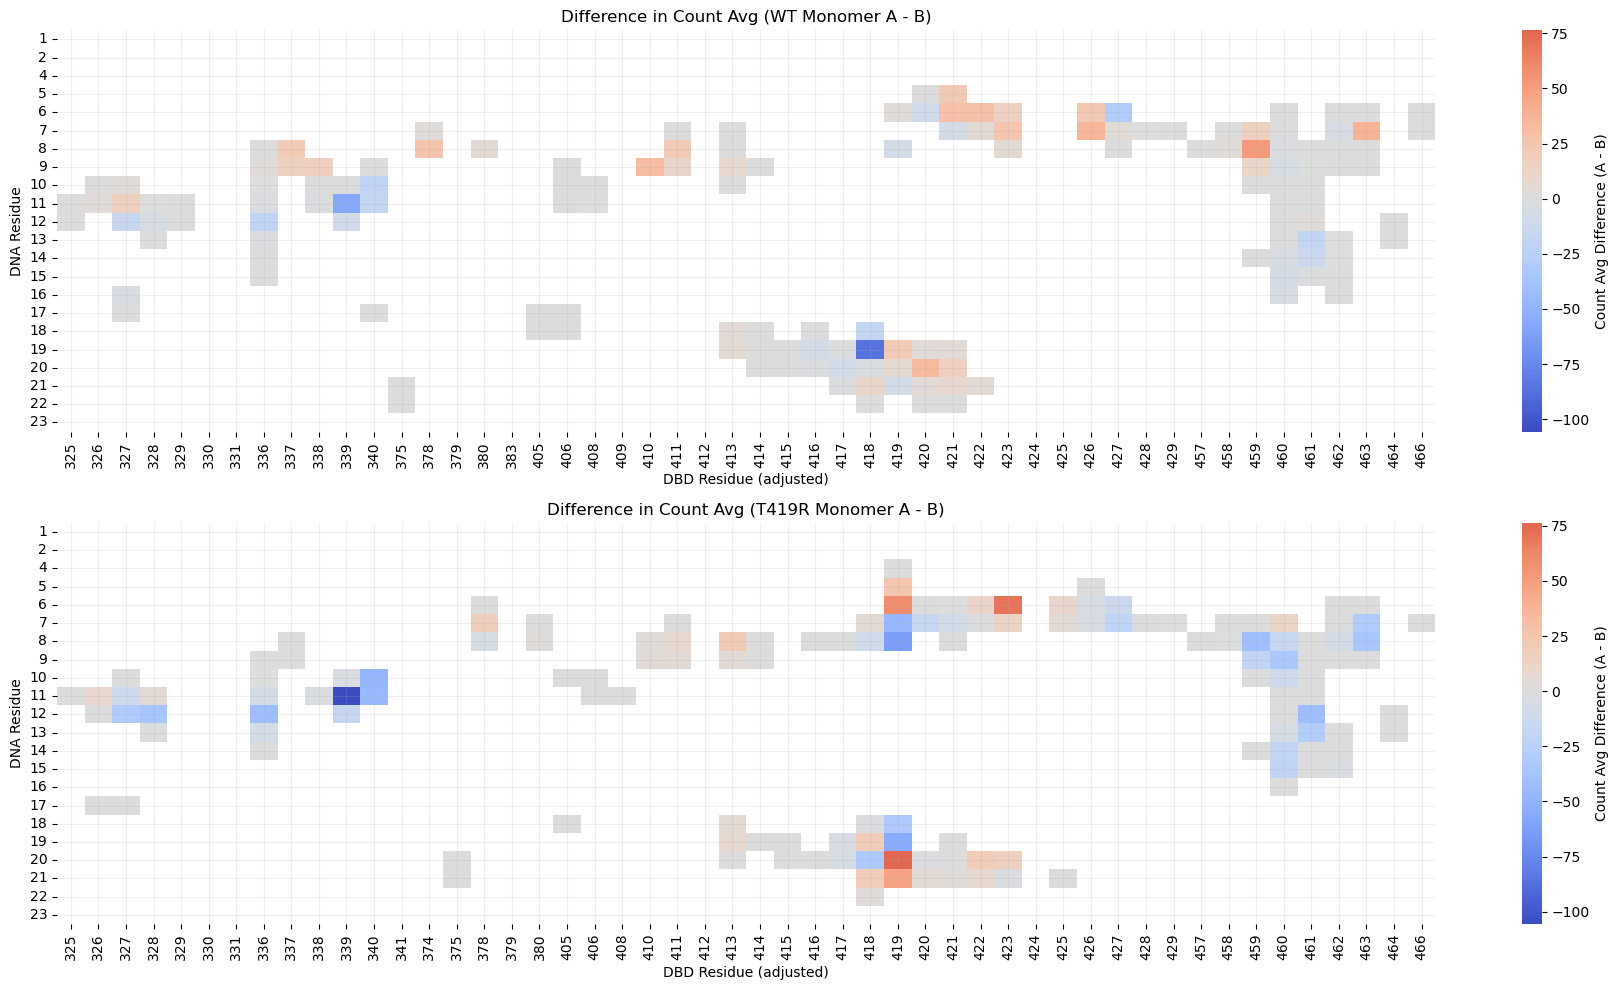

In [135]:
diff_dbd_wt_pivot = wt_dbd_monoA_pivot - wt_dbd_monoB_pivot
diff_dbd_mut_pivot = mut_dbd_monoA_pivot - mut_dbd_monoB_pivot

# Find global min and max
all_data = [
    diff_dbd_wt_pivot.values,
    diff_dbd_mut_pivot.values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), sharey=True)

# WT
sns.heatmap(diff_dbd_wt_pivot, cmap='coolwarm', center=0, ax=ax1, vmin=global_min, vmax=global_max, cbar_kws={'label': 'Count Avg Difference (A - B)'})
ax1.set_title('Difference in Count Avg (WT Monomer A - B)')
ax1.set_xlabel('DBD Residue (adjusted)')
ax1.set_ylabel('DNA Residue')
ax1.grid(alpha = 0.2)

# Monomer B
sns.heatmap(diff_dbd_mut_pivot, cmap='coolwarm', center=0, ax=ax2, vmin=global_min, vmax=global_max, cbar_kws={'label': 'Count Avg Difference (A - B)'})
ax2.set_title('Difference in Count Avg (T419R Monomer A - B)')
ax2.set_xlabel('DBD Residue (adjusted)')
ax2.set_ylabel('DNA Residue')
ax2.grid(alpha = 0.2)

plt.tight_layout()
plt.show()

#### By monomer and DNA strand

In [ ]:
wt_dbd_agg_monoA_C = wt_dbd_agg[(wt_dbd_agg['sele1_chain'] == 'A') & (wt_dbd_agg['sele2_chain'] == 'C')]
wt_dbd_agg_monoA_D = wt_dbd_agg[(wt_dbd_agg['sele1_chain'] == 'A') & (wt_dbd_agg['sele2_chain'] == 'D')]
wt_dbd_agg_monoB_C = wt_dbd_agg[(wt_dbd_agg['sele1_chain'] == 'B') & (wt_dbd_agg['sele2_chain'] == 'C')]
wt_dbd_agg_monoB_D = wt_dbd_agg[(wt_dbd_agg['sele1_chain'] == 'B') & (wt_dbd_agg['sele2_chain'] == 'D')]

wt_dbd_monoA_C_pivot = pivotdf_count_avg(wt_dbd_agg_monoA_C)
wt_dbd_monoA_D_pivot = pivotdf_count_avg(wt_dbd_agg_monoA_D)
wt_dbd_monoB_C_pivot = pivotdf_count_avg(wt_dbd_agg_monoB_C)
wt_dbd_monoB_D_pivot = pivotdf_count_avg(wt_dbd_agg_monoB_D)

T419R_dbd_agg_monoA_C = T419R_dbd_agg[(T419R_dbd_agg['sele1_chain'] == 'A') & (T419R_dbd_agg['sele2_chain'] == 'C')]
T419R_dbd_agg_monoA_D = T419R_dbd_agg[(T419R_dbd_agg['sele1_chain'] == 'A') & (T419R_dbd_agg['sele2_chain'] == 'D')]
T419R_dbd_agg_monoB_C = T419R_dbd_agg[(T419R_dbd_agg['sele1_chain'] == 'B') & (T419R_dbd_agg['sele2_chain'] == 'C')]
T419R_dbd_agg_monoB_D = T419R_dbd_agg[(T419R_dbd_agg['sele1_chain'] == 'B') & (T419R_dbd_agg['sele2_chain'] == 'D')]

mut_dbd_monoA_C_pivot = pivotdf_count_avg(T419R_dbd_agg_monoA_C)
mut_dbd_monoA_D_pivot = pivotdf_count_avg(T419R_dbd_agg_monoA_D)
mut_dbd_monoB_C_pivot = pivotdf_count_avg(T419R_dbd_agg_monoB_C)
mut_dbd_monoB_D_pivot = pivotdf_count_avg(T419R_dbd_agg_monoB_D)

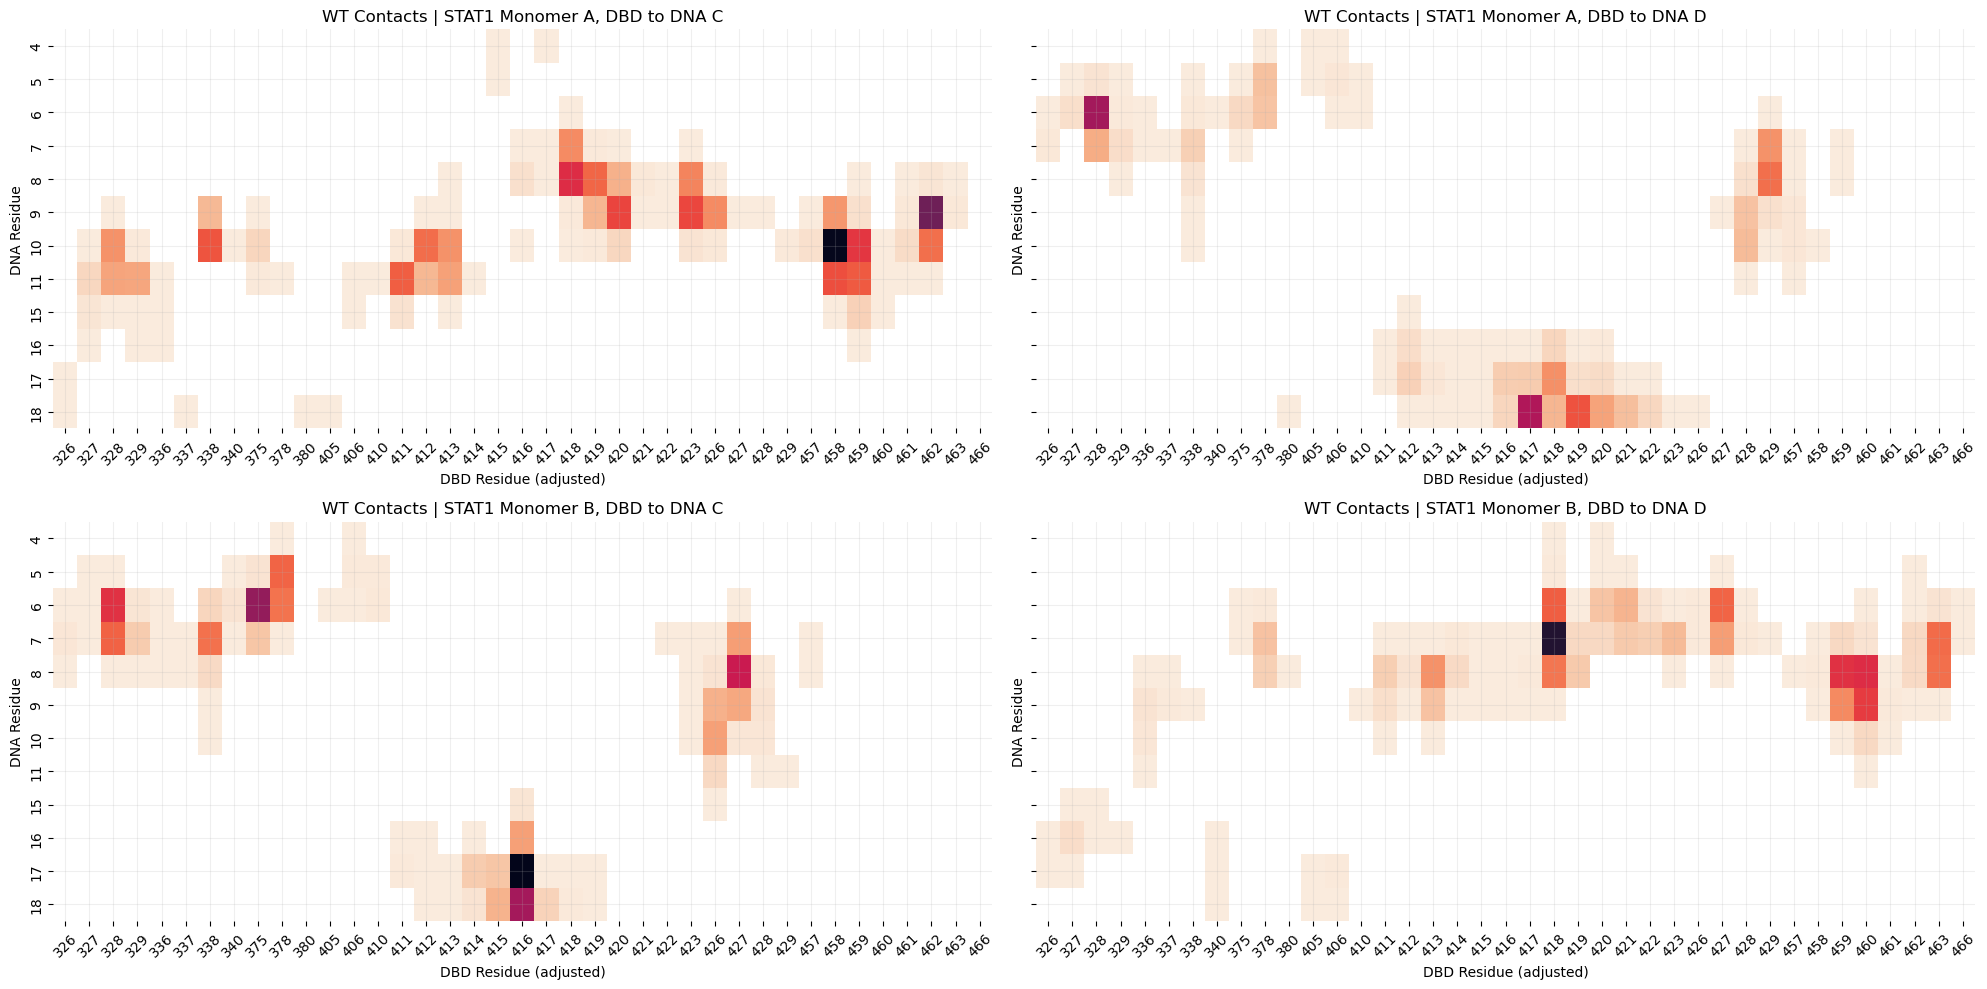

In [137]:
# Find global min and max
all_data = [
    wt_dbd_monoA_C_pivot.values,
    wt_dbd_monoA_D_pivot.values,
    wt_dbd_monoB_C_pivot.values,
    wt_dbd_monoB_D_pivot.values
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(20, 10), sharey=True, sharex=True)
ax1, ax2, ax3, ax4 = axes.flatten()
plots = [
    (wt_dbd_monoA_C_pivot, ax1, 'WT Contacts | STAT1 Monomer A, DBD to DNA C'),
    (wt_dbd_monoA_D_pivot, ax2, 'WT Contacts | STAT1 Monomer A, DBD to DNA D'),
    (wt_dbd_monoB_C_pivot, ax3, 'WT Contacts | STAT1 Monomer B, DBD to DNA C'),
    (wt_dbd_monoB_D_pivot, ax4, 'WT Contacts | STAT1 Monomer B, DBD to DNA D')
]

for pivot_df, ax, title in plots:
    sns.heatmap(
        pivot_df, 
        cmap='rocket_r', 
        ax=ax, 
        cbar=False, 
        vmin=global_min, 
        vmax=global_max
    )
    ax.set_title(title)
    ax.set_xlabel('DBD Residue (adjusted)')
    ax.set_ylabel('DNA Residue')
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45, labelbottom=True)

plt.tight_layout()
plt.show()

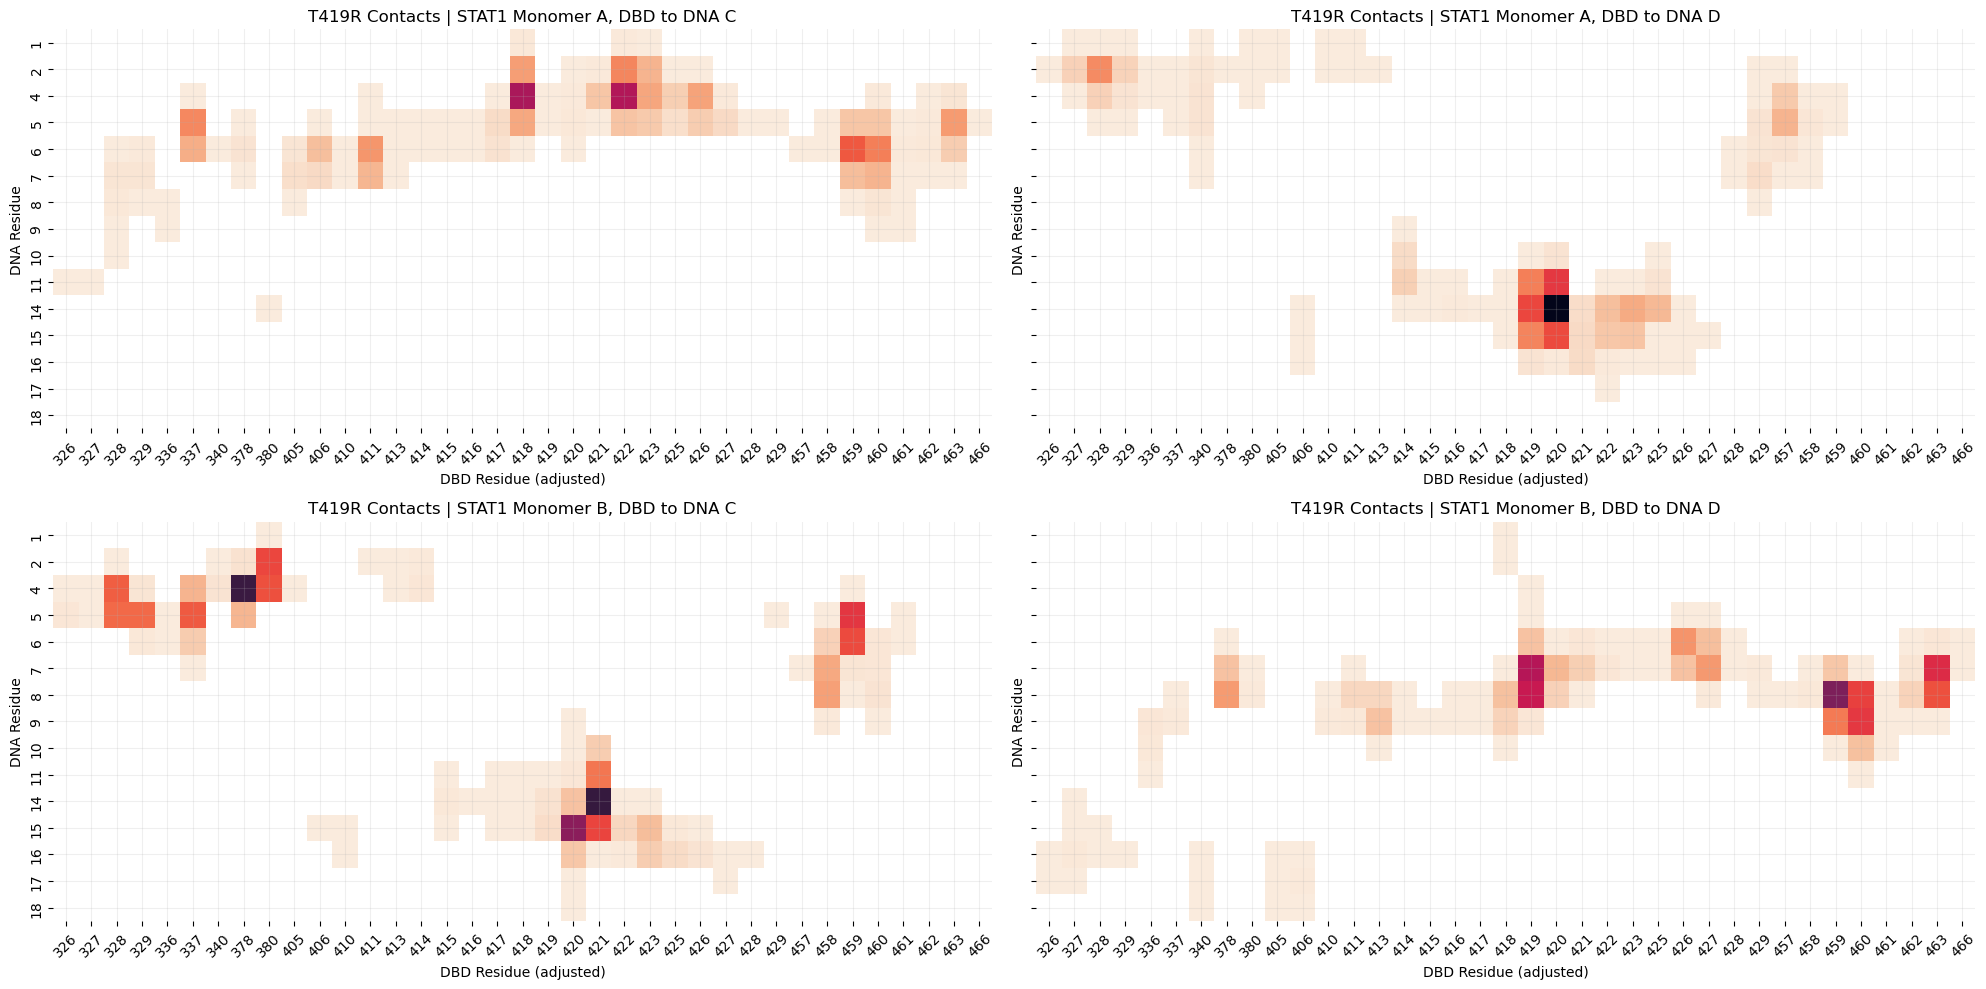

In [138]:
# Find global min and max
all_data = [
    mut_dbd_monoA_C_pivot.values,
    mut_dbd_monoA_D_pivot.values,
    mut_dbd_monoB_C_pivot.values,
    mut_dbd_monoB_D_pivot.values
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(20, 10), sharey=True, sharex=True)
ax1, ax2, ax3, ax4 = axes.flatten()
plots = [
    (mut_dbd_monoA_C_pivot, ax1, 'T419R Contacts | STAT1 Monomer A, DBD to DNA C'),
    (mut_dbd_monoA_D_pivot, ax2, 'T419R Contacts | STAT1 Monomer A, DBD to DNA D'),
    (mut_dbd_monoB_C_pivot, ax3, 'T419R Contacts | STAT1 Monomer B, DBD to DNA C'),
    (mut_dbd_monoB_D_pivot, ax4, 'T419R Contacts | STAT1 Monomer B, DBD to DNA D')
]

for pivot_df, ax, title in plots:
    sns.heatmap(
        pivot_df, 
        cmap='rocket_r', 
        ax=ax, 
        cbar=False, 
        vmin=global_min, 
        vmax=global_max
    )
    ax.set_title(title)
    ax.set_xlabel('DBD Residue (adjusted)')
    ax.set_ylabel('DNA Residue')
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45, labelbottom=True)

plt.tight_layout()
plt.show()

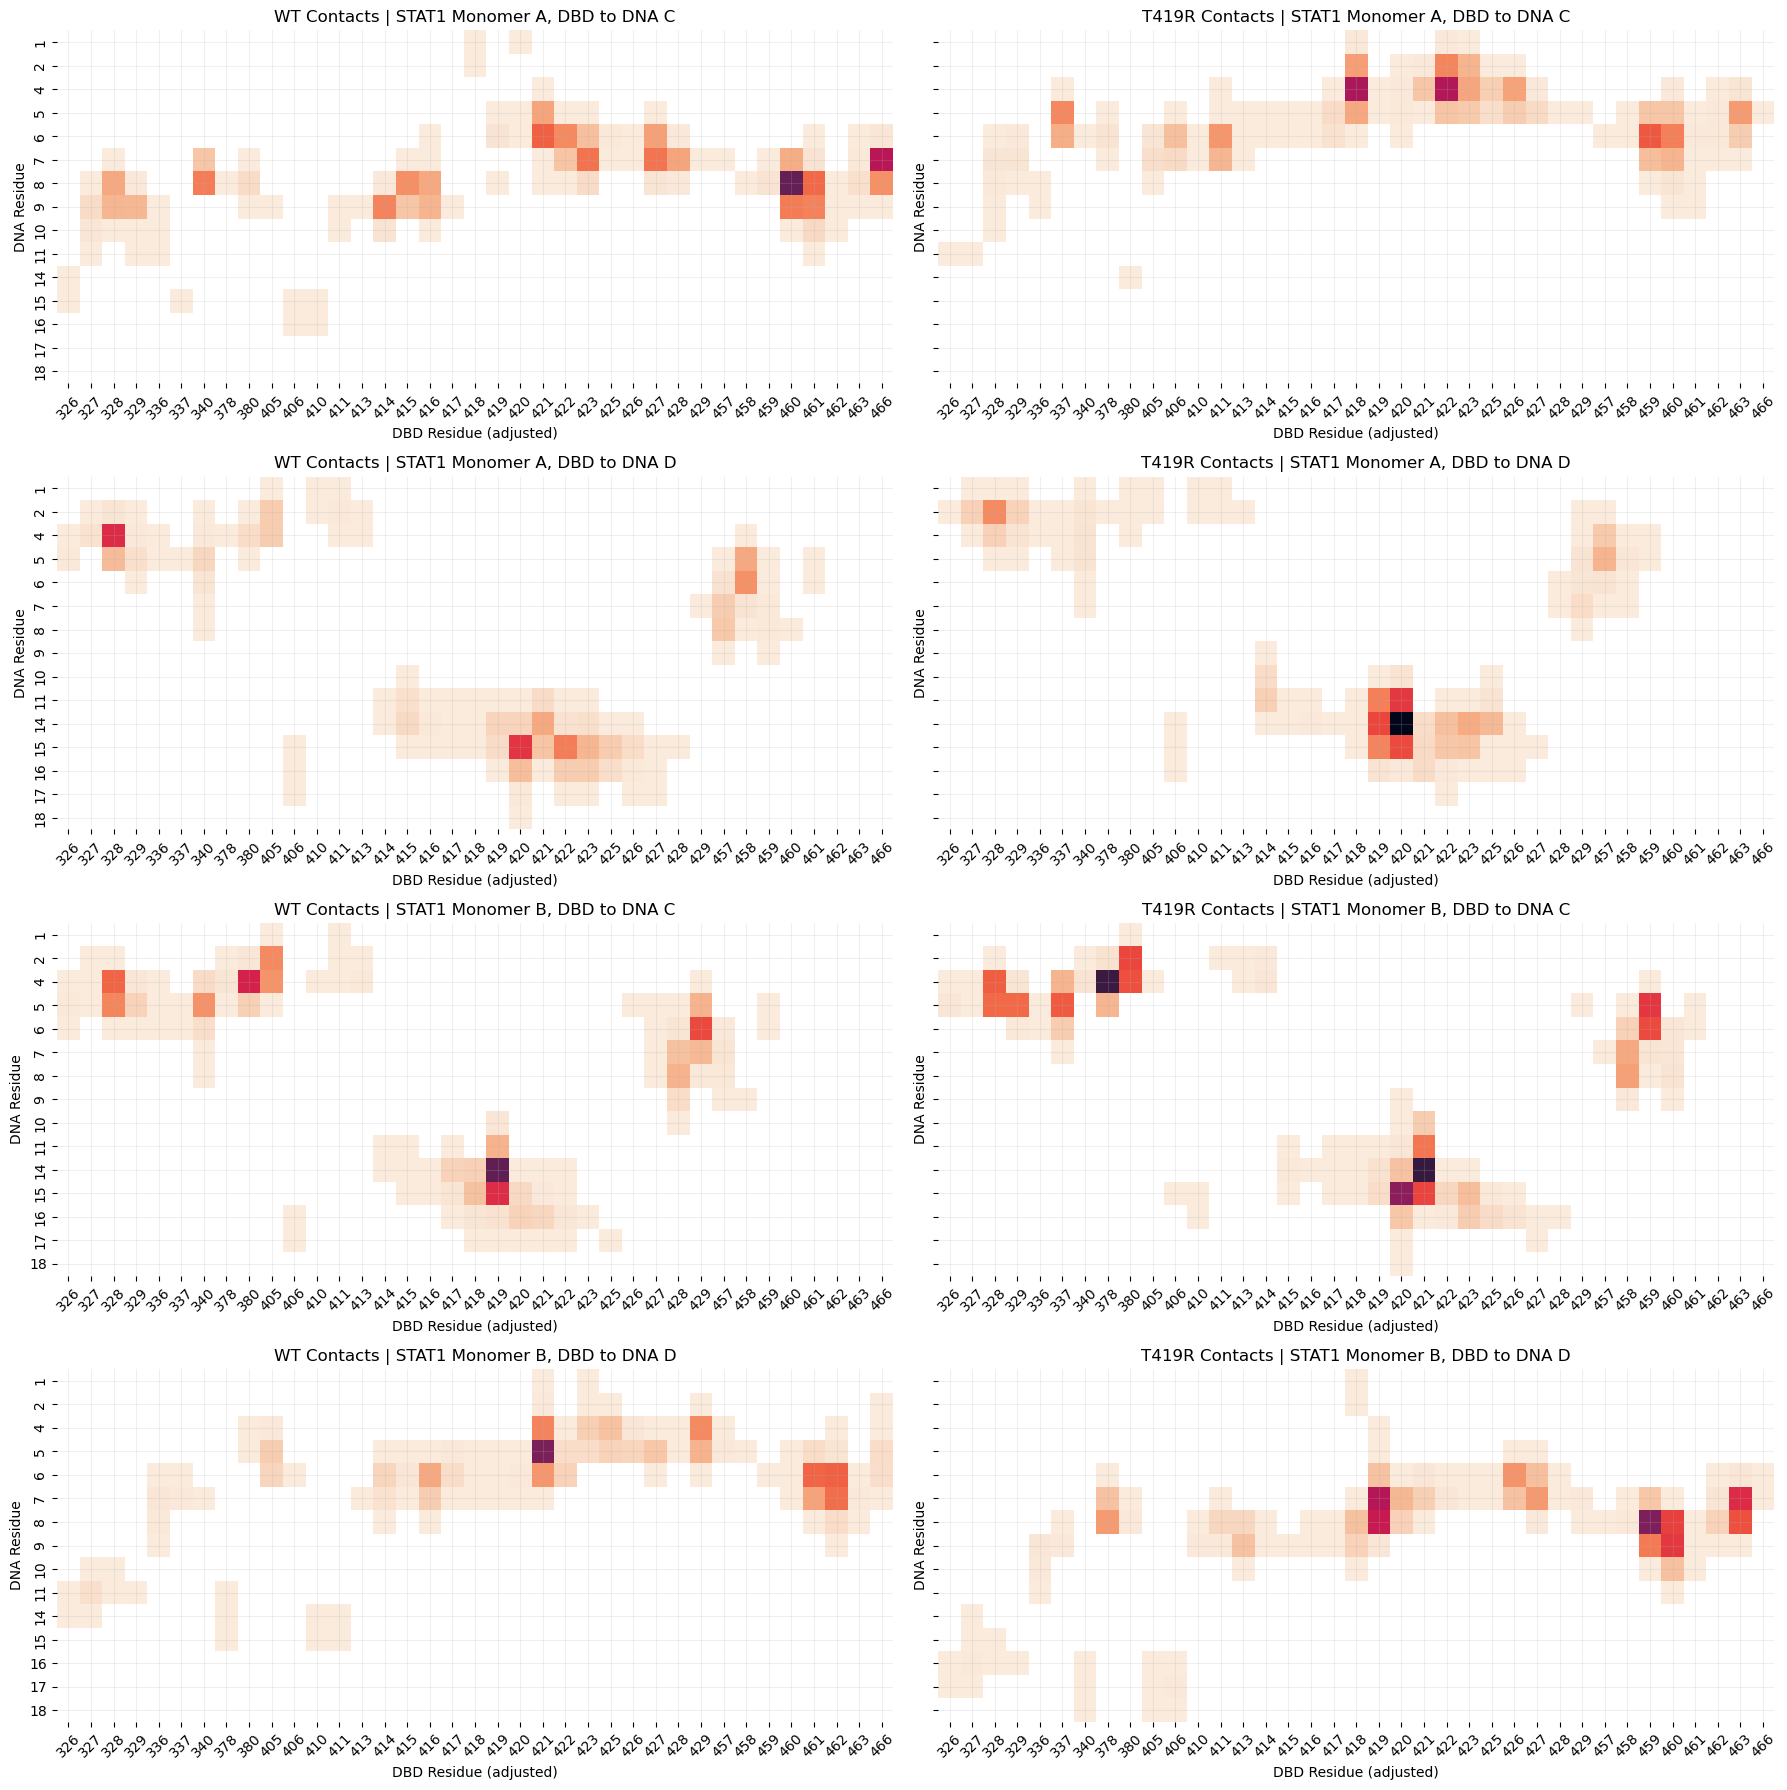

In [139]:
# Find global min and max
all_data = [
    wt_dbd_monoA_C_pivot.values,
    wt_dbd_monoA_D_pivot.values,
    wt_dbd_monoB_C_pivot.values,
    wt_dbd_monoB_D_pivot.values,
    mut_dbd_monoA_C_pivot.values,
    mut_dbd_monoA_D_pivot.values,
    mut_dbd_monoB_C_pivot.values,
    mut_dbd_monoB_D_pivot.values
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(4, 2, figsize=(18, 18), sharey=True, sharex=True)
ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8 = axes.flatten()

plots = [
    (wt_dbd_monoA_C_pivot, ax1, 'WT Contacts | STAT1 Monomer A, DBD to DNA C'),
    (mut_dbd_monoA_C_pivot, ax2, 'T419R Contacts | STAT1 Monomer A, DBD to DNA C'),
    (wt_dbd_monoA_D_pivot, ax3, 'WT Contacts | STAT1 Monomer A, DBD to DNA D'),
    (mut_dbd_monoA_D_pivot, ax4, 'T419R Contacts | STAT1 Monomer A, DBD to DNA D'),
    (wt_dbd_monoB_C_pivot, ax5, 'WT Contacts | STAT1 Monomer B, DBD to DNA C'),
    (mut_dbd_monoB_C_pivot, ax6, 'T419R Contacts | STAT1 Monomer B, DBD to DNA C'),
    (wt_dbd_monoB_D_pivot, ax7, 'WT Contacts | STAT1 Monomer B, DBD to DNA D'),
    (mut_dbd_monoB_D_pivot, ax8, 'T419R Contacts | STAT1 Monomer B, DBD to DNA D'),
]

for pivot_df, ax, title in plots:
    sns.heatmap(
        pivot_df, 
        cmap='rocket_r', 
        ax=ax, 
        cbar=False, 
        vmin=global_min, 
        vmax=global_max
    )
    ax.set_title(title)
    ax.set_xlabel('DBD Residue (adjusted)')
    ax.set_ylabel('DNA Residue')
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45, labelbottom=True)

plt.tight_layout()
plt.show()

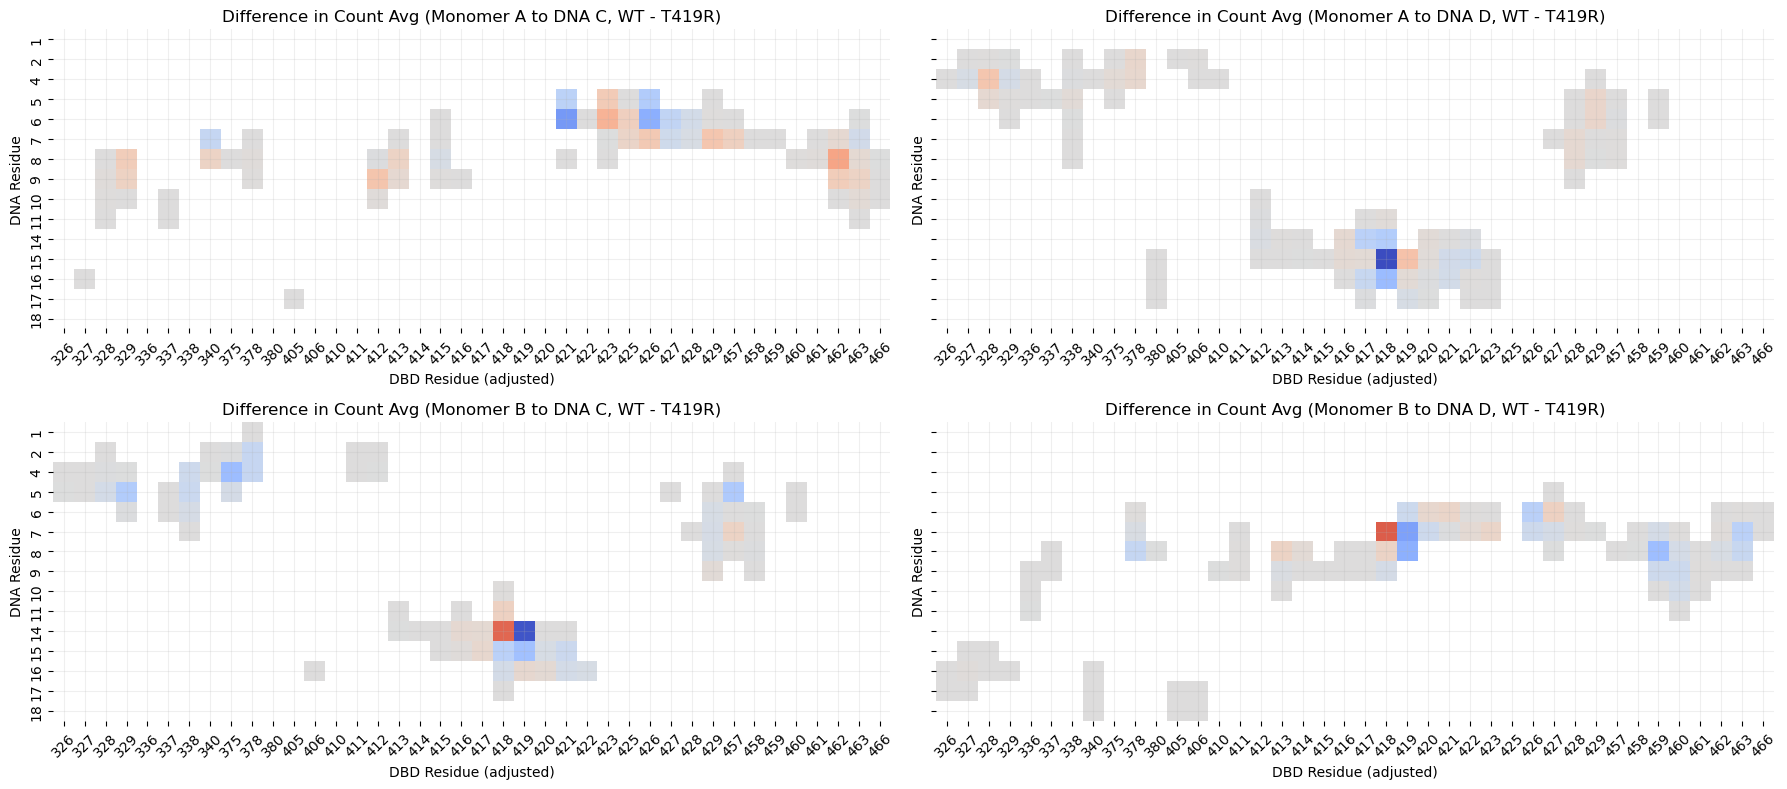

In [140]:
diff_dbd_wt_monoA_C_mut_monoA_C = wt_dbd_monoA_C_pivot - mut_dbd_monoA_C_pivot
diff_dbd_wt_monoA_D_mut_monoA_D = wt_dbd_monoA_D_pivot - mut_dbd_monoA_D_pivot
diff_dbd_wt_monoB_C_mut_monoB_C = wt_dbd_monoB_C_pivot - mut_dbd_monoB_C_pivot
diff_dbd_wt_monoB_D_mut_monoB_D = wt_dbd_monoB_D_pivot - mut_dbd_monoB_D_pivot

# Find global min and max
all_data = [
    diff_dbd_wt_monoA_C_mut_monoA_C.values,
    diff_dbd_wt_monoA_D_mut_monoA_D.values,
    diff_dbd_wt_monoB_C_mut_monoB_C.values,
    diff_dbd_wt_monoB_D_mut_monoB_D.values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(18, 8), sharey=True, sharex=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (diff_dbd_wt_monoA_C_mut_monoA_C, ax1, 'Difference in Count Avg (Monomer A to DNA C, WT - T419R)'),
    (diff_dbd_wt_monoA_D_mut_monoA_D, ax2, 'Difference in Count Avg (Monomer A to DNA D, WT - T419R)'),
    (diff_dbd_wt_monoB_C_mut_monoB_C, ax3, 'Difference in Count Avg (Monomer B to DNA C, WT - T419R)'),
    (diff_dbd_wt_monoB_D_mut_monoB_D, ax4, 'Difference in Count Avg (Monomer B to DNA D, WT - T419R)'),
]

for pivot_df, ax, title in plots:
    sns.heatmap(
        pivot_df, 
        cmap='coolwarm', 
        ax=ax, 
        cbar=False, 
        center=0,
        vmin=global_min, 
        vmax=global_max
    )
    ax.set_title(title)
    ax.set_xlabel('DBD Residue (adjusted)')
    ax.set_ylabel('DNA Residue')
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45, labelbottom=True)

plt.tight_layout()
plt.show()

#### Filter out (potential) hydrogen bonds

A separate analysis focuses on hydrogen bonds, with a distance threshold of < 3.5 Å. Applying a distance filter removes these from the contact results.

In [141]:
def aggregate_pairs_filter(df_list):
    combined = pd.concat(df_list)
    combined = combined[combined['distance'] > 3.5]
    agg_df = combined.groupby(['sele1_resnm', 'sele1_resid_adj', 
                               'sele2_resnm', 'sele2_resid_adj']).size().reset_index(name='count')
    
    return agg_df

In [ ]:
wt_dbd_agg_filtered = aggregate_pairs_filter(wt_dbd_dfs)
T419R_dbd_agg_filtered = aggregate_pairs_filter(T419R_dbd_dfs)

wt_dbd_agg_filtered["count_avg"] = wt_dbd_agg_filtered["count"] / (len(wt_dbd_dfs)* 1000)
T419R_dbd_agg_filtered["count_avg"] = T419R_dbd_agg_filtered["count"] / (len(T419R_dbd_dfs)* 1000)

wt_dbd_pivot_filtered = pivotdf_count_avg(wt_dbd_agg_filtered)
mut_dbd_pivot_filtered = pivotdf_count_avg(T419R_dbd_agg_filtered)

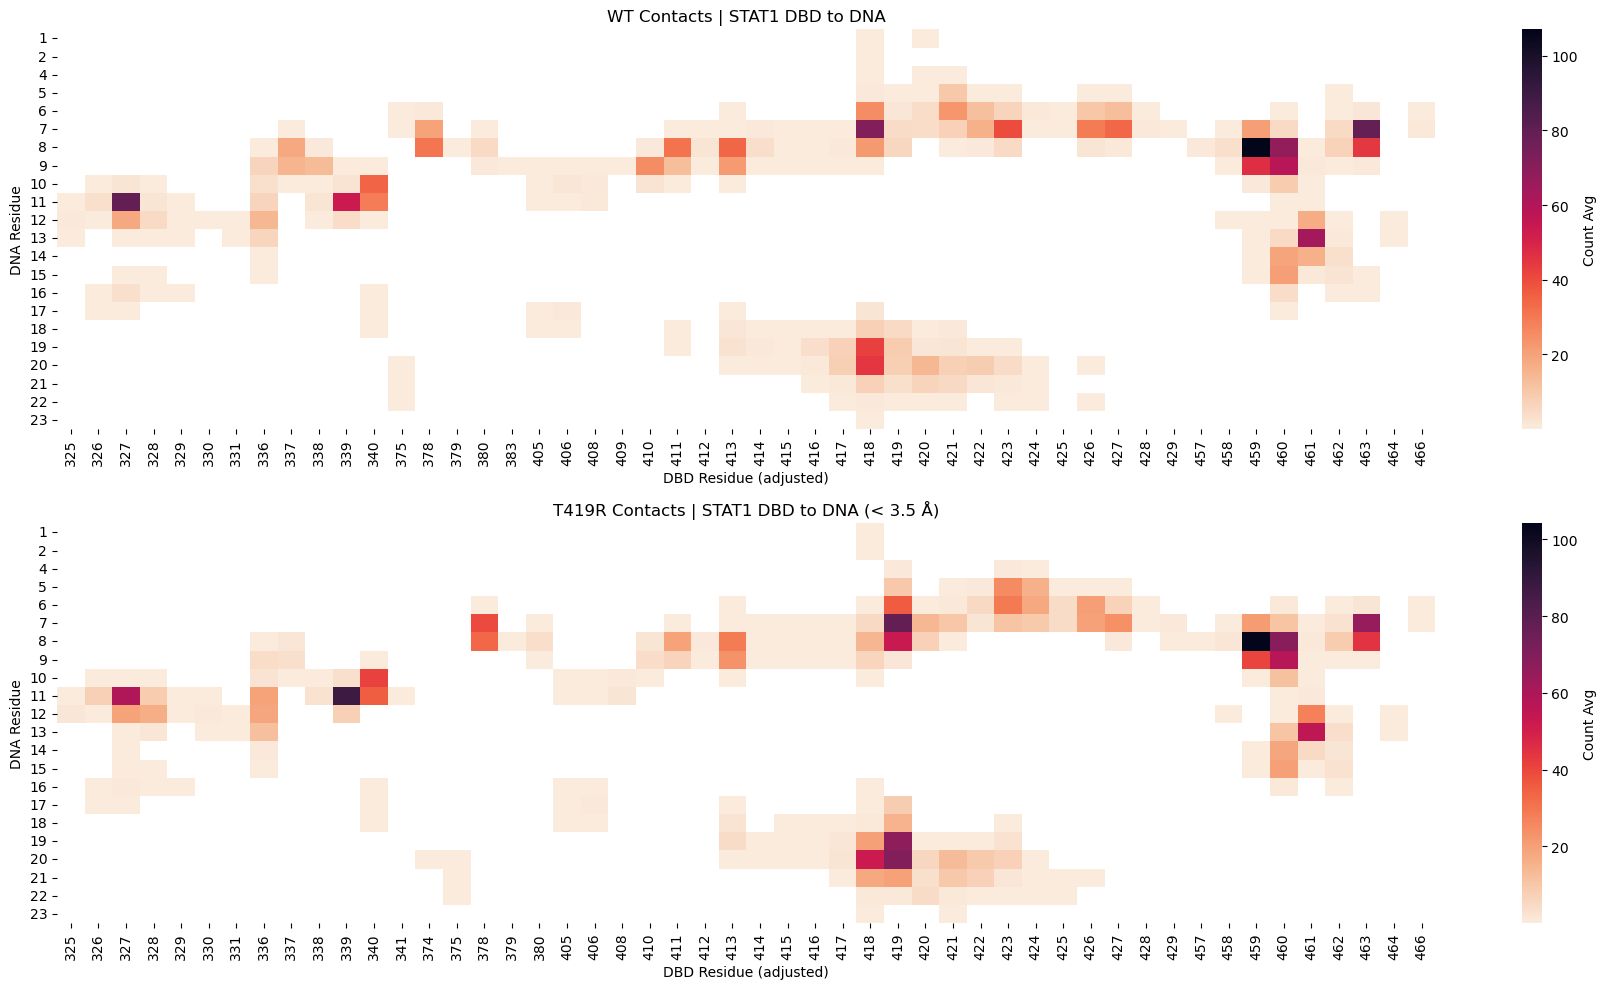

In [143]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), sharey=True)

# WT heatmap
sns.heatmap(wt_dbd_pivot_filtered, cmap='rocket_r', ax=ax1, cbar_kws={'label': 'Count Avg'})
ax1.set_title('WT Contacts | STAT1 DBD to DNA')
ax1.set_xlabel('DBD Residue (adjusted)')
ax1.set_ylabel('DNA Residue')

# T419R heatmap
sns.heatmap(mut_dbd_pivot_filtered, cmap='rocket_r', ax=ax2, cbar_kws={'label': 'Count Avg'})
ax2.set_title('T419R Contacts | STAT1 DBD to DNA (< 3.5 Å)')
ax2.set_xlabel('DBD Residue (adjusted)')
ax2.set_ylabel('DNA Residue')

plt.tight_layout()
plt.show()

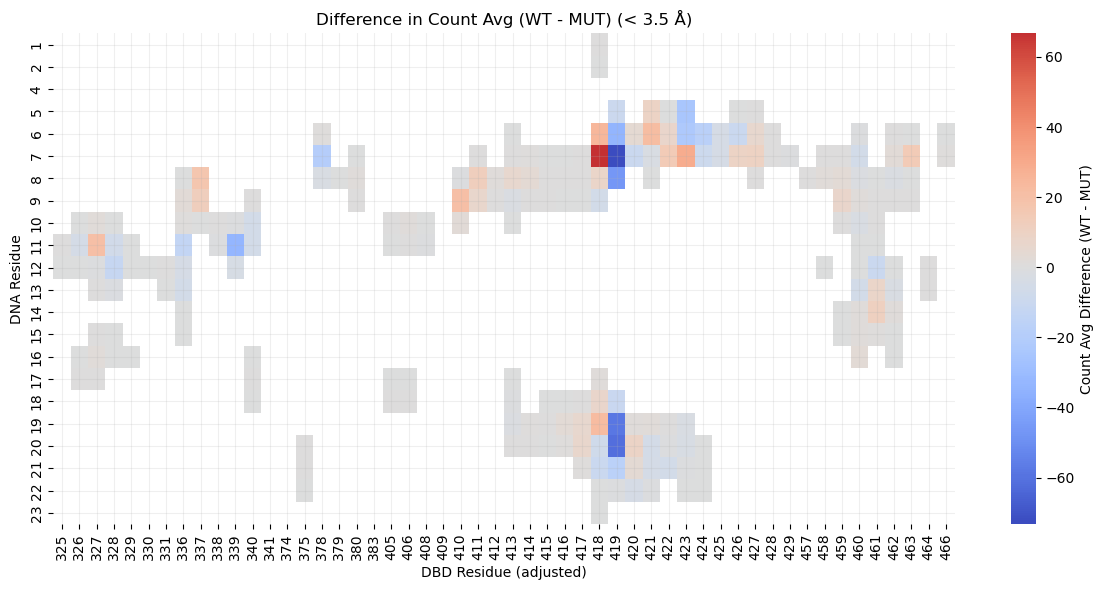

In [144]:
diff_dbd_pivot_filtered = wt_dbd_pivot_filtered - mut_dbd_pivot_filtered

plt.figure(figsize=(12, 6))

sns.heatmap(diff_dbd_pivot_filtered, cmap='coolwarm', center=0, cbar_kws={'label': 'Count Avg Difference (WT - MUT)'})
plt.title('Difference in Count Avg (WT - MUT) (< 3.5 Å)')
plt.xlabel('DBD Residue (adjusted)')
plt.ylabel('DNA Residue')

plt.grid(alpha = 0.2)
plt.tight_layout()
plt.show()

## Full protein with DNA

### Load data

In [38]:
wt_full_dfs = []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/004.contacts/pairs_full.csv')
    wt_full_dfs.append(df)

T419R_full_dfs = []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/T419R/rep{rep}/analysis/004.contacts/pairs_full.csv')
    T419R_full_dfs.append(df)

In [39]:
wt_full_dfs[0].head()

,frame,sele1_resid,sele1_resnm,sele1_chain,sele2_resid,sele2_resnm,sele2_chain,distance
0,1000,190,MET,A,12,DG,D,4.907506
1,1000,190,MET,A,12,DG,D,4.486903
2,1000,192,THR,A,12,DG,D,4.632156
3,1000,192,THR,A,11,DC,D,4.287577
4,1000,192,THR,A,11,DC,D,4.939452


### Preprocessing

Adjust residue numbers.

In [40]:
adjust_resid(wt_full_dfs + T419R_full_dfs)

In [41]:
wt_full_dfs[0].head()

,frame,sele1_resid,sele1_resnm,sele1_chain,sele2_resid,sele2_resnm,sele2_chain,distance,sele1_resid_adj,sele2_resid_adj
0,1000,190,MET,A,12,DG,D,4.907506,325,12
1,1000,190,MET,A,12,DG,D,4.486903,325,12
2,1000,192,THR,A,12,DG,D,4.632156,327,12
3,1000,192,THR,A,11,DC,D,4.287577,327,11
4,1000,192,THR,A,11,DC,D,4.939452,327,11


In [145]:
wt_full_agg = aggregate_pairs(wt_full_dfs)
T419R_full_agg = aggregate_pairs(T419R_full_dfs)

In [146]:
wt_full_agg.sort_values('count', ascending=False).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg
39,ARG,418,B,DG,19,C,283033,4.145784
393,SER,459,A,DT,8,C,278783,4.098669
41,ARG,418,B,DT,7,D,257178,4.160853
137,GLN,463,A,DT,7,C,202698,4.101309
486,VAL,339,B,DC,11,C,178984,4.136174
432,THR,327,A,DC,11,D,168211,4.138601
37,ARG,418,B,DC,20,C,167178,4.146232
29,ARG,418,A,DG,20,D,159261,4.104046
510,VAL,461,B,DG,13,C,142352,4.174150
103,ASN,460,B,DT,8,D,125384,4.173410


In [147]:
wt_full_agg["count_avg"] = wt_full_agg["count"] / (len(wt_full_dfs)* 1000)
T419R_full_agg["count_avg"] = T419R_full_agg["count"] / (len(T419R_full_dfs)* 1000)

In [148]:
wt_full_agg.sort_values('count_avg', ascending=False).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg,count_avg
39,ARG,418,B,DG,19,C,283033,4.145784,94.344333
393,SER,459,A,DT,8,C,278783,4.098669,92.927667
41,ARG,418,B,DT,7,D,257178,4.160853,85.726000
137,GLN,463,A,DT,7,C,202698,4.101309,67.566000
486,VAL,339,B,DC,11,C,178984,4.136174,59.661333
432,THR,327,A,DC,11,D,168211,4.138601,56.070333
37,ARG,418,B,DC,20,C,167178,4.146232,55.726000
29,ARG,418,A,DG,20,D,159261,4.104046,53.087000
510,VAL,461,B,DG,13,C,142352,4.174150,47.450667
103,ASN,460,B,DT,8,D,125384,4.173410,41.794667


In [149]:
T419R_full_agg.sort_values('count_avg', ascending=False).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg,count_avg
50,ARG,419,A,DG,20,D,375678,4.113897,125.226000
61,ARG,419,B,DG,19,C,322140,4.185668,107.380000
449,VAL,339,B,DC,11,C,317278,4.126990,105.759333
384,SER,459,B,DT,8,D,256219,4.106231,85.406333
36,ARG,418,B,DC,20,C,243926,4.122768,81.308667
49,ARG,419,A,DG,6,C,217687,4.179055,72.562333
361,PRO,423,A,DG,6,C,211016,4.152988,70.338667
62,ARG,419,B,DT,7,D,207056,4.236805,69.018667
63,ARG,419,B,DT,8,D,190097,4.149556,63.365667
140,GLN,463,B,DT,7,D,167593,4.124034,55.864333


In [150]:
T419R_full_agg[(T419R_full_agg['sele1_resid_adj'] == 419) & (T419R_full_agg['sele2_resid_adj'] == 7)].sort_values('count_avg', ascending=False).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg,count_avg
62,ARG,419,B,DT,7,D,207056,4.236805,69.018667
51,ARG,419,A,DT,7,C,64759,4.123403,21.586333


In [151]:
wt_full_agg[(wt_full_agg['sele1_resid_adj'] == 418) & (wt_full_agg['sele2_resid_adj'] == 7)].sort_values('count_avg', ascending=False).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg,count_avg
41,ARG,418,B,DT,7,D,257178,4.160853,85.726


### Comparison

#### By average count

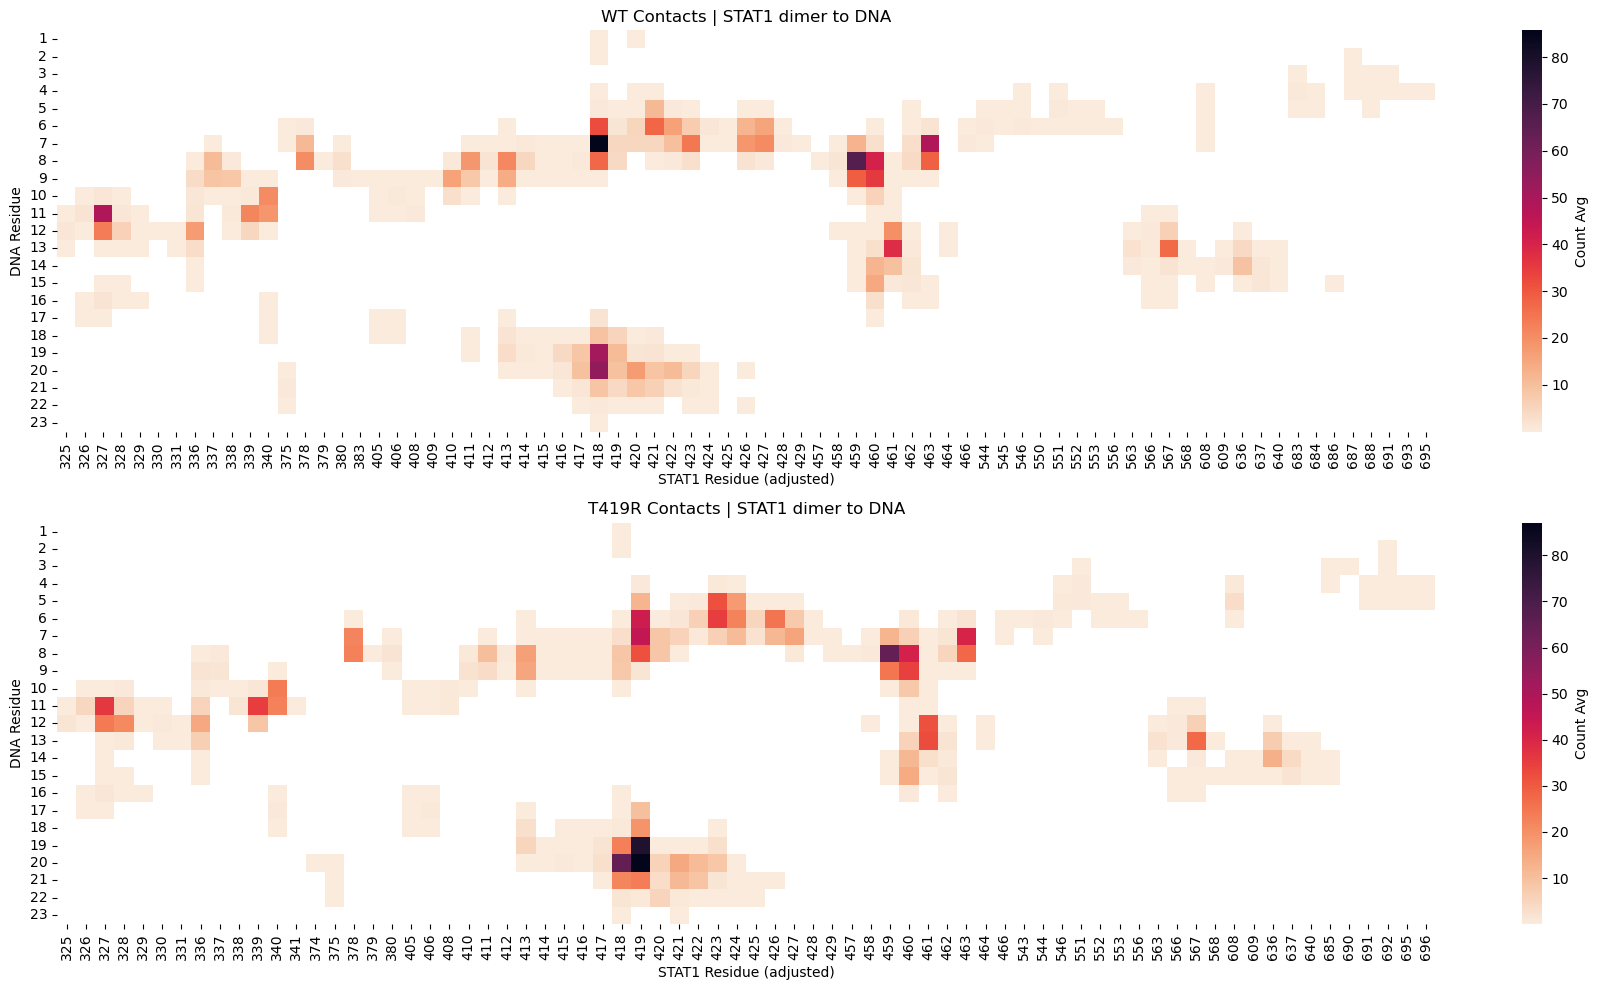

In [ ]:
wt_full_pivot = pivotdf_count_avg(wt_full_agg)
mut_full_pivot = pivotdf_count_avg(T419R_full_agg)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), sharey=True)

# WT heatmap
sns.heatmap(wt_full_pivot, cmap='rocket_r', ax=ax1, cbar_kws={'label': 'Count Avg'})
ax1.set_title('WT Contacts | STAT1 dimer to DNA')
ax1.set_xlabel('STAT1 Residue (adjusted)')
ax1.set_ylabel('DNA Residue')

# T419R heatmap
sns.heatmap(mut_full_pivot, cmap='rocket_r', ax=ax2, cbar_kws={'label': 'Count Avg'})
ax2.set_title('T419R Contacts | STAT1 dimer to DNA')
ax2.set_xlabel('STAT1 Residue (adjusted)')
ax2.set_ylabel('DNA Residue')

plt.tight_layout()
plt.show()

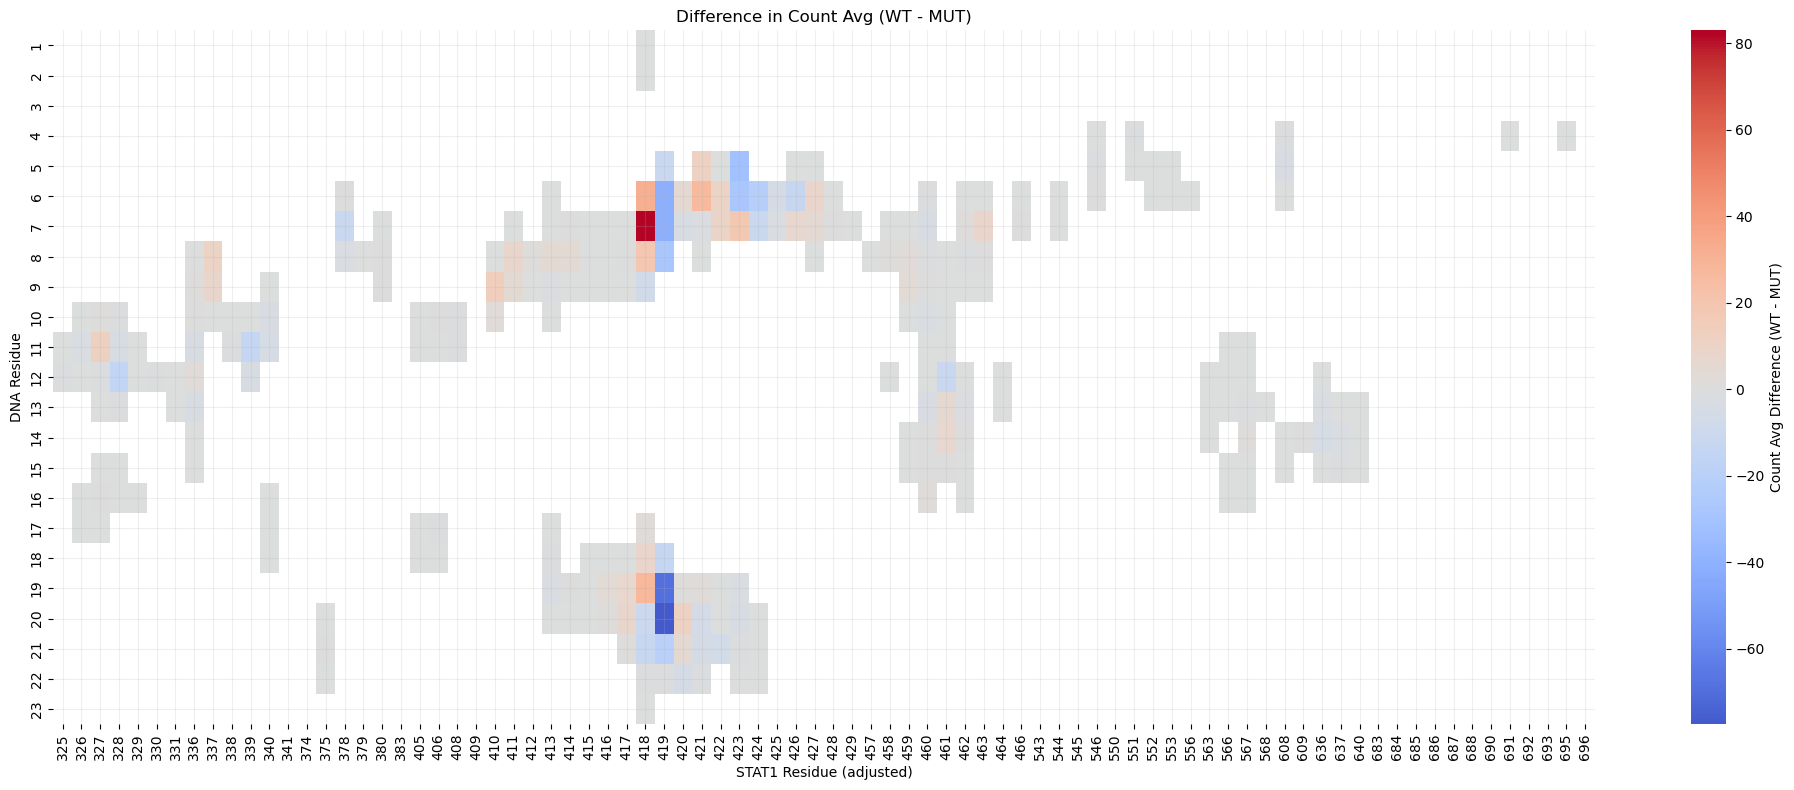

In [153]:
diff_full_pivot = wt_full_pivot - mut_full_pivot

plt.figure(figsize=(20, 8))

sns.heatmap(diff_full_pivot, cmap='coolwarm', center=0, cbar_kws={'label': 'Count Avg Difference (WT - MUT)'})
plt.title('Difference in Count Avg (WT - MUT)')
plt.xlabel('STAT1 Residue (adjusted)')
plt.ylabel('DNA Residue')

plt.grid(alpha = 0.2)
plt.tight_layout()
plt.show()

#### By average distance

In [159]:
def pivotdf_distance_avg(df):
    pivot = df.pivot_table(values='distance_avg', 
                          index='sele2_resid_adj', 
                          columns='sele1_resid_adj', 
                          aggfunc='mean')
    return pivot

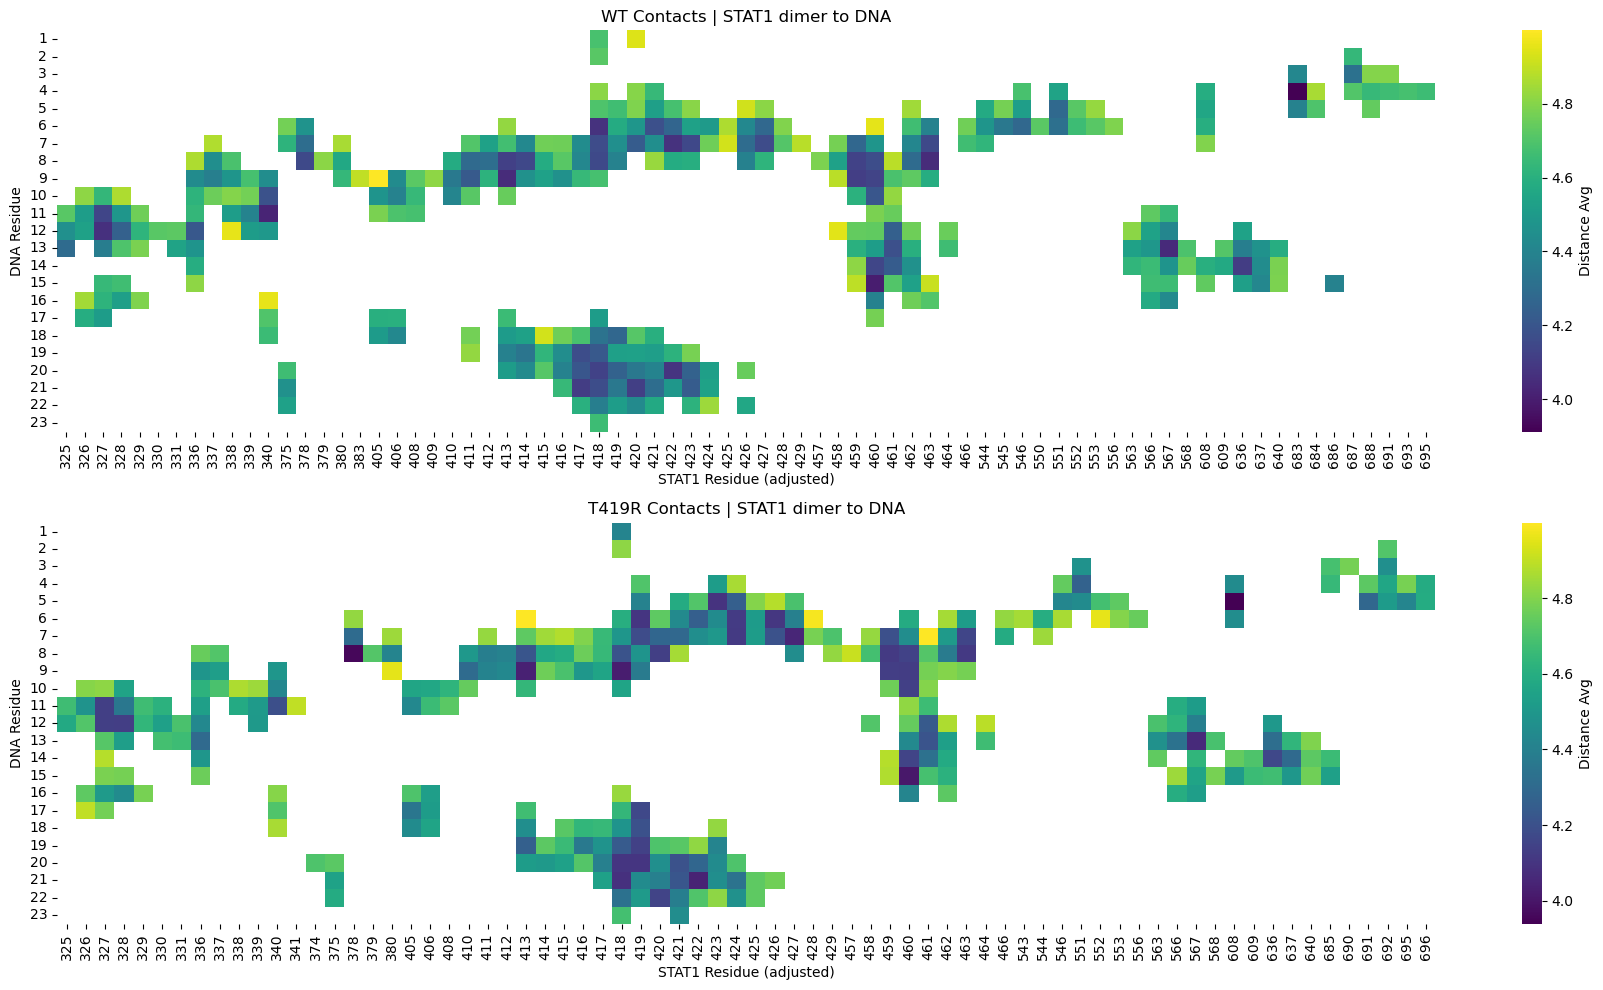

In [161]:
wt_full_pivot = pivotdf_distance_avg(wt_full_agg)
mut_full_pivot = pivotdf_distance_avg(T419R_full_agg)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), sharey=True)

# WT heatmap
sns.heatmap(wt_full_pivot, cmap='viridis', ax=ax1, cbar_kws={'label': 'Distance Avg'})
ax1.set_title('WT Contacts | STAT1 dimer to DNA')
ax1.set_xlabel('STAT1 Residue (adjusted)')
ax1.set_ylabel('DNA Residue')

# T419R heatmap
sns.heatmap(mut_full_pivot, cmap='viridis', ax=ax2, cbar_kws={'label': 'Distance Avg'})
ax2.set_title('T419R Contacts | STAT1 dimer to DNA')
ax2.set_xlabel('STAT1 Residue (adjusted)')
ax2.set_ylabel('DNA Residue')

plt.tight_layout()
plt.show()

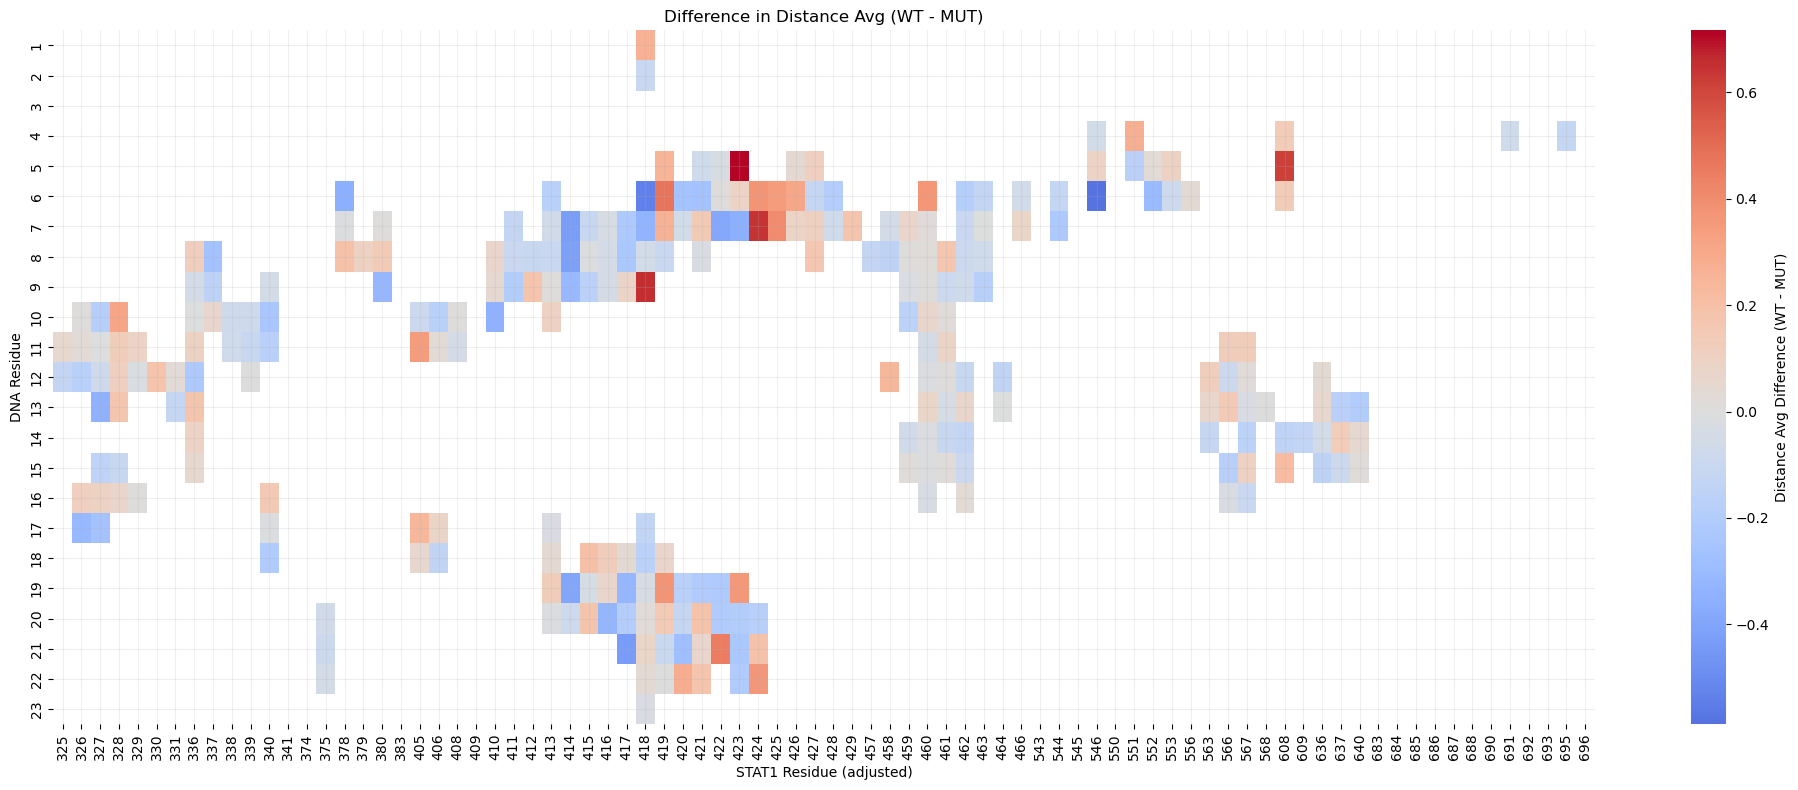

In [162]:
diff_full_pivot = wt_full_pivot - mut_full_pivot

plt.figure(figsize=(20, 8))

sns.heatmap(diff_full_pivot, cmap='coolwarm', center=0, cbar_kws={'label': 'Distance Avg Difference (WT - MUT)'})
plt.title('Difference in Distance Avg (WT - MUT)')
plt.xlabel('STAT1 Residue (adjusted)')
plt.ylabel('DNA Residue')

plt.grid(alpha = 0.2)
plt.tight_layout()
plt.show()

In [164]:
wt_full_agg_monoA_C = wt_full_agg[(wt_full_agg['sele1_chain'] == 'A') & (wt_full_agg['sele2_chain'] == 'C')]
wt_full_agg_monoA_D = wt_full_agg[(wt_full_agg['sele1_chain'] == 'A') & (wt_full_agg['sele2_chain'] == 'D')]
wt_full_agg_monoB_C = wt_full_agg[(wt_full_agg['sele1_chain'] == 'B') & (wt_full_agg['sele2_chain'] == 'C')]
wt_full_agg_monoB_D = wt_full_agg[(wt_full_agg['sele1_chain'] == 'B') & (wt_full_agg['sele2_chain'] == 'D')]

wt_full_monoA_C_pivot = pivotdf_distance_avg(wt_full_agg_monoA_C)
wt_full_monoA_D_pivot = pivotdf_distance_avg(wt_full_agg_monoA_D)
wt_full_monoB_C_pivot = pivotdf_distance_avg(wt_full_agg_monoB_C)
wt_full_monoB_D_pivot = pivotdf_distance_avg(wt_full_agg_monoB_D)

T419R_full_agg_monoA_C = T419R_full_agg[(T419R_full_agg['sele1_chain'] == 'A') & (T419R_full_agg['sele2_chain'] == 'C')]
T419R_full_agg_monoA_D = T419R_full_agg[(T419R_full_agg['sele1_chain'] == 'A') & (T419R_full_agg['sele2_chain'] == 'D')]
T419R_full_agg_monoB_C = T419R_full_agg[(T419R_full_agg['sele1_chain'] == 'B') & (T419R_full_agg['sele2_chain'] == 'C')]
T419R_full_agg_monoB_D = T419R_full_agg[(T419R_full_agg['sele1_chain'] == 'B') & (T419R_full_agg['sele2_chain'] == 'D')]

mut_full_monoA_C_pivot = pivotdf_distance_avg(T419R_full_agg_monoA_C)
mut_full_monoA_D_pivot = pivotdf_distance_avg(T419R_full_agg_monoA_D)
mut_full_monoB_C_pivot = pivotdf_distance_avg(T419R_full_agg_monoB_C)
mut_full_monoB_D_pivot = pivotdf_distance_avg(T419R_full_agg_monoB_D)

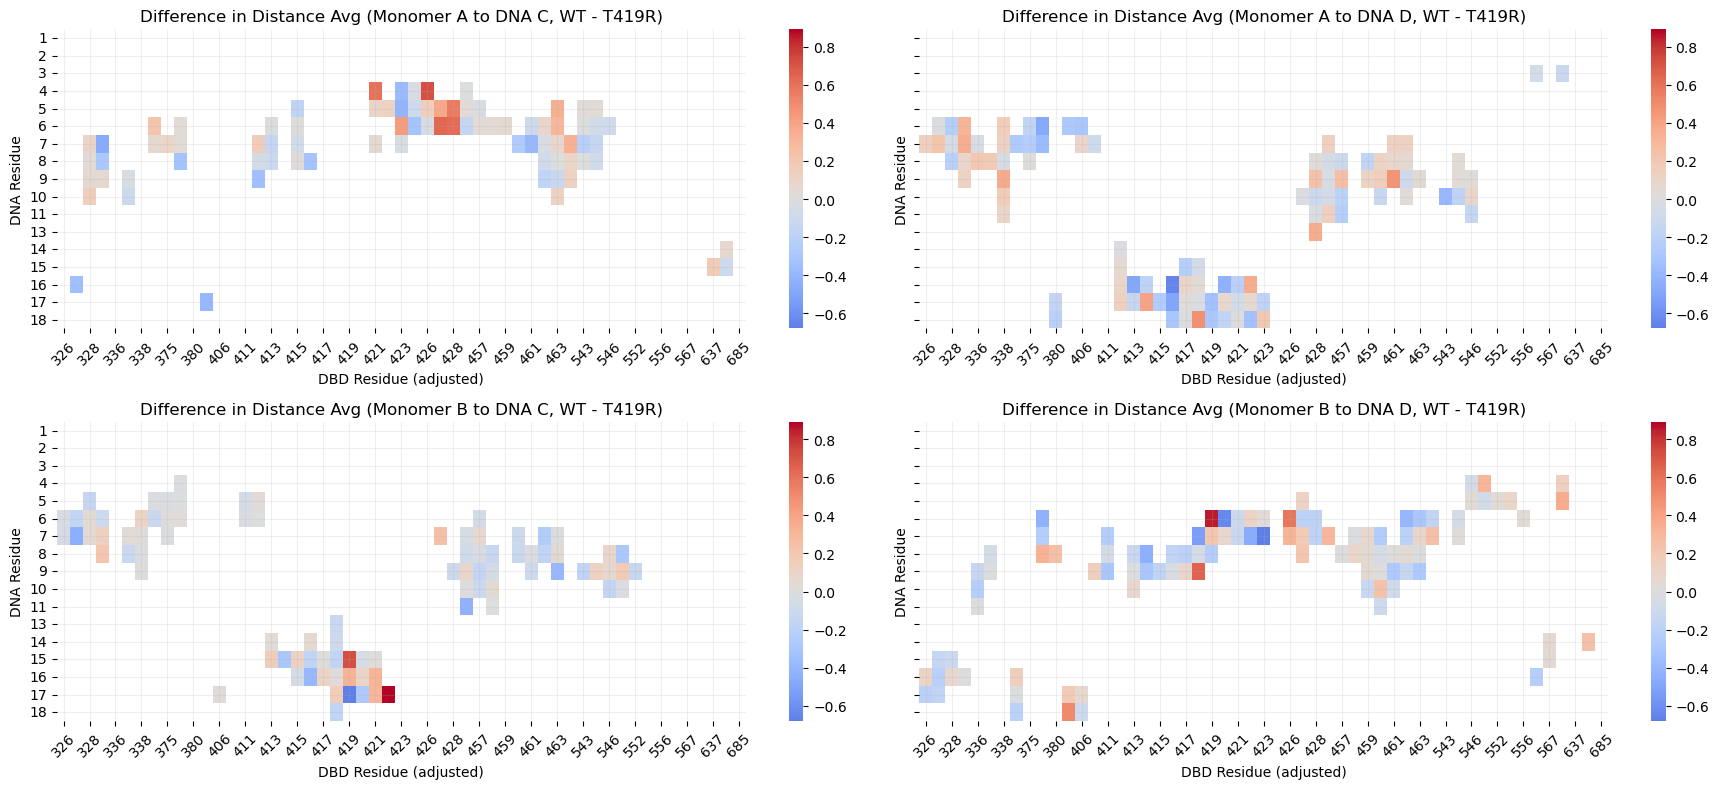

In [166]:
diff_full_wt_monoA_C_mut_monoA_C = wt_full_monoA_C_pivot - mut_full_monoA_C_pivot
diff_full_wt_monoA_D_mut_monoA_D = wt_full_monoA_D_pivot - mut_full_monoA_D_pivot
diff_full_wt_monoB_C_mut_monoB_C = wt_full_monoB_C_pivot - mut_full_monoB_C_pivot
diff_full_wt_monoB_D_mut_monoB_D = wt_full_monoB_D_pivot - mut_full_monoB_D_pivot

# Find global min and max
all_data = [
    diff_full_wt_monoA_C_mut_monoA_C.values,
    diff_full_wt_monoA_D_mut_monoA_D.values,
    diff_full_wt_monoB_C_mut_monoB_C.values,
    diff_full_wt_monoB_D_mut_monoB_D.values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(18, 8), sharey=True, sharex=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (diff_full_wt_monoA_C_mut_monoA_C, ax1, 'Difference in Distance Avg (Monomer A to DNA C, WT - T419R)'),
    (diff_full_wt_monoA_D_mut_monoA_D, ax2, 'Difference in Distance Avg (Monomer A to DNA D, WT - T419R)'),
    (diff_full_wt_monoB_C_mut_monoB_C, ax3, 'Difference in Distance Avg (Monomer B to DNA C, WT - T419R)'),
    (diff_full_wt_monoB_D_mut_monoB_D, ax4, 'Difference in Distance Avg (Monomer B to DNA D, WT - T419R)'),
]

for pivot_df, ax, title in plots:
    sns.heatmap(
        pivot_df, 
        cmap='coolwarm', 
        ax=ax, 
        cbar=True, 
        center=0,
        vmin=global_min, 
        vmax=global_max
    )
    ax.set_title(title)
    ax.set_xlabel('DBD Residue (adjusted)')
    ax.set_ylabel('DNA Residue')
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45, labelbottom=True)

plt.tight_layout()
plt.show()

#### Statistical significance (Mann-Whitney U)

In [49]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import acf
import os

In [50]:
wt_data = pd.concat(wt_full_dfs, ignore_index=True)
T419R_data = pd.concat(T419R_full_dfs, ignore_index=True)

In [51]:
# Define residue pair identifier
def create_pair_id(row):
    return f"{row['sele1_resid']}_{row['sele1_chain']}-{row['sele2_resid']}_{row['sele2_chain']}"

Mann-Whitney U test

In [52]:
wt_data['pair_id'] = wt_data.apply(create_pair_id, axis=1)
T419R_data['pair_id'] = T419R_data.apply(create_pair_id, axis=1)

# Get unique residue pairs present in either condition
all_pairs = set(wt_data['pair_id']).union(set(T419R_data['pair_id']))

# Store results
results = []

# Perform Mann-Whitney U test for each residue pair
for pair in all_pairs:
    # Extract distances for this pair in each condition
    dist_wt = wt_data[wt_data['pair_id'] == pair]['distance'].values
    dist_T419R = T419R_data[T419R_data['pair_id'] == pair]['distance'].values
    
    # Skip if either condition has no data or insufficient data
    if len(dist_wt) < 2 or len(dist_T419R) < 2:
        continue
    
    # Perform Mann-Whitney U test
    stat, p_value = mannwhitneyu(dist_wt, dist_T419R, alternative='two-sided')
    
    # Store result
    sele1, sele2 = pair.split('-')
    sele1_resid, sele1_chain = sele1.split('_')
    sele2_resid, sele2_chain = sele2.split('_')
    results.append({
        'pair': pair,
        'sele1': sele1,
        'sele2': sele2,
        'sele1_resid': int(sele1_resid) + 135,
        'sele1_chain': sele1_chain,
        'sele2_resid': int(sele2_resid),
        'sele2_chain': sele2_chain,
        'u_statistic': stat,
        'p_value': p_value,
        'n_cond1': len(dist_wt),
        'n_cond2': len(dist_T419R)
    })

# Convert results to dataframe
mannwhitney_df = pd.DataFrame(results)

In [77]:
mannwhitney_df[['pair', 'n_cond1', 'n_cond2']].sort_values(['n_cond1', 'n_cond2'], ascending=False).head(10)

,pair,n_cond1,n_cond2
166,283_B-19_C,283033,40103
351,324_A-8_C,278783,131373
331,283_B-7_D,257178,1061
145,328_A-7_C,202698,76491
309,204_B-11_C,178984,317278
17,192_A-11_D,168211,90320
139,283_B-20_C,167178,243926
319,283_A-20_D,159261,145012
282,326_B-13_C,142352,141327
253,325_B-8_D,125384,148784


Check ACF correlation score between timeframes

In [53]:
# Parameters
lags = 50  # Maximum lags for ACF computation
acf_threshold = 0.1  # Threshold for significant autocorrelation
output_dir = "acf_analysis"
os.makedirs(output_dir, exist_ok=True)

# Get unique residue pairs
unique_pairs = wt_data['pair_id'].unique()

# Initialize results list
results_acf = []

# Compute ACF metrics for each pair
for pair_id in unique_pairs:
    # Extract distance data
    pair_data = wt_data[wt_data['pair_id'] == pair_id]['distance'].dropna()
    
    # Skip if insufficient data
    if len(pair_data) < 2:
        print(f"Skipping pair {pair_id}: insufficient data ({len(pair_data)} points)")
        continue
    
    # Compute ACF
    try:
        acf_values = acf(pair_data, nlags=min(lags, len(pair_data)-1), fft=True)
    except Exception as e:
        print(f"Error computing ACF for pair {pair_id}: {e}")
        continue
    
    # Metric 1: Lag where ACF drops below threshold
    significant_lags = np.where(np.abs(acf_values) < acf_threshold)[0]
    lag_to_threshold = significant_lags[0] if len(significant_lags) > 0 else len(acf_values)
    
    # Metric 2: Sum of absolute ACF values (excluding lag 0)
    sum_abs_acf = np.sum(np.abs(acf_values[1:]))  # Skip lag 0 (always 1)
    
    # Metric 3: Effective sample size
    # n_eff = n / (1 + 2 * sum(ACF_k for k=1 to infinity))
    sum_acf = np.sum(acf_values[1:])  # Sum positive ACF for approximation
    n = len(pair_data)
    n_eff = n / (1 + 2 * sum_acf) if (1 + 2 * sum_acf) > 0 else n
    
    # Store results
    results_acf.append({
        'pair_id': pair_id,
        'n_points': n,
        'lag_to_threshold': lag_to_threshold,
        'sum_abs_acf': sum_abs_acf,
        'n_eff': n_eff
    })

# Create results dataframe
results_acf_df = pd.DataFrame(results_acf)


Skipping pair 415_A-6_C: insufficient data (1 points)
Skipping pair 328_A-15_D: insufficient data (1 points)
Skipping pair 270_B-11_C: insufficient data (1 points)
Skipping pair 473_A-15_D: insufficient data (1 points)
Skipping pair 558_B-4_C: insufficient data (1 points)
Skipping pair 325_B-6_D: insufficient data (1 points)
Skipping pair 203_B-12_C: insufficient data (1 points)
Skipping pair 281_A-18_D: insufficient data (1 points)
Skipping pair 190_B-13_C: insufficient data (1 points)
Skipping pair 552_A-2_D: insufficient data (1 points)
Skipping pair 280_A-18_D: insufficient data (1 points)
Skipping pair 203_A-11_C: insufficient data (1 points)
Skipping pair 553_B-5_C: insufficient data (1 points)
Skipping pair 270_A-9_D: insufficient data (1 points)
Skipping pair 194_B-11_C: insufficient data (1 points)
Skipping pair 240_B-22_C: insufficient data (1 points)
Skipping pair 205_B-16_D: insufficient data (1 points)
Skipping pair 326_A-8_C: insufficient data (1 points)
Skipping pair 324

In [54]:
results_acf_df.head()

,pair_id,n_points,lag_to_threshold,sum_abs_acf,n_eff
0,190_A-12_D,3098,1,2.244748,568.649687
1,192_A-12_D,46233,3,4.472638,5813.958897
2,192_A-11_D,168211,3,1.282405,136363.515405
3,201_A-9_C,15151,8,4.053376,1663.710519
4,201_A-10_C,5463,1,2.593215,883.061794


In [55]:

# Sort by lag_to_threshold (descending) to highlight pairs with persistent correlation
results_acf_df = results_acf_df.sort_values('lag_to_threshold', ascending=False)

# Save results to CSV
results_acf_df.to_csv(os.path.join(output_dir, 'acf_metrics.csv'), index=False)


In [56]:
# Summary statistics
print(f"Analyzed {len(results_acf_df)} residue pairs.")
print(f"Mean lag to threshold (ACF < {acf_threshold}): {results_acf_df['lag_to_threshold'].mean():.2f}")
print(f"Max lag to threshold: {results_acf_df['lag_to_threshold'].max()}")
print(f"Pairs with lag_to_threshold > 10: {len(results_acf_df[results_acf_df['lag_to_threshold'] > 10])}")
print(f"Results saved to '{output_dir}/acf_metrics.csv'")

Analyzed 495 residue pairs.
Mean lag to threshold (ACF < 0.1): 3.85
Max lag to threshold: 51
Pairs with lag_to_threshold > 10: 24
Results saved to 'acf_analysis/acf_metrics.csv'


In [57]:
results_acf_df[results_acf_df['lag_to_threshold'] > 10].sort_values('lag_to_threshold', ascending=False)

,pair_id,n_points,lag_to_threshold,sum_abs_acf,n_eff
22,283_A-19_D,23469,51,7.056713,1552.857689
131,201_A-11_D,2633,51,7.363233,167.424783
37,291_A-8_C,6392,51,9.177619,330.246516
46,325_A-7_C,8770,51,7.641818,538.577490
70,190_B-12_C,3463,51,11.843764,140.273253
244,325_B-13_C,6466,51,9.562083,321.305226
124,328_B-9_D,798,51,9.181189,41.213946
39,292_A-8_C,2897,47,7.604235,184.465431
194,327_B-13_C,2462,39,7.626463,151.480413
129,190_A-11_D,458,36,9.150621,23.729044


There are 24 residue pairs (out of 495) with a relatively high autocorrelation. This is not a very high ratio and the max lag_to_threshold, 51, is relatively low compared to the 1000 analyzed frames. This should not have a large influence in the overall analysis. However, it is worth noting that one of the residue pairs with the maximum lag to threshold value is 283_A-19D, which after adjusting the residue numbers equals 418 A to 19 D. This residue is next to mutated residue 419 and, as seen in other analysis, the interactions with residue 418 are often affected by the mutation, as interactions are displaced towards the more positive ARG. When looking at the significance for this pair, one should keep in mind that it might be less reliable than for the less-strongly correlated pairs.

In [58]:
# Adjust p-values for multiple testing
# Bonferroni
mannwhitney_df['p_adjusted_bonferroni'] = multipletests(mannwhitney_df['p_value'], method='bonferroni')[1]
# Benjamini-Hochberg
mannwhitney_df['p_adjusted_bh'] = multipletests(mannwhitney_df['p_value'], method='fdr_bh')[1]

In [59]:
mannwhitney_df.head()

,pair,sele1,sele2,sele1_resid,sele1_chain,sele2_resid,sele2_chain,u_statistic,p_value,n_cond1,n_cond2,p_adjusted_bonferroni,p_adjusted_bh
0,501_A-14_D,501_A,14_D,636,A,14,D,9779622.0,4.434618e-29,8358,2729,1.578724e-26,1.578724e-28
1,331_B-6_D,331_B,6_D,466,B,6,D,12.0,7.997936e-02,4,15,1.000000e+00,1.086742e-01
2,193_B-15_D,193_B,15_D,328,B,15,D,296.0,5.381026e-02,29,29,1.000000e+00,7.693354e-02
3,418_B-5_D,418_B,5_D,553,B,5,D,1198.0,3.909382e-02,14,128,1.000000e+00,5.703852e-02
4,286_A-22_D,286_A,22_D,421,A,22,D,113681.0,3.559673e-04,64,2818,1.267244e-01,6.400220e-04


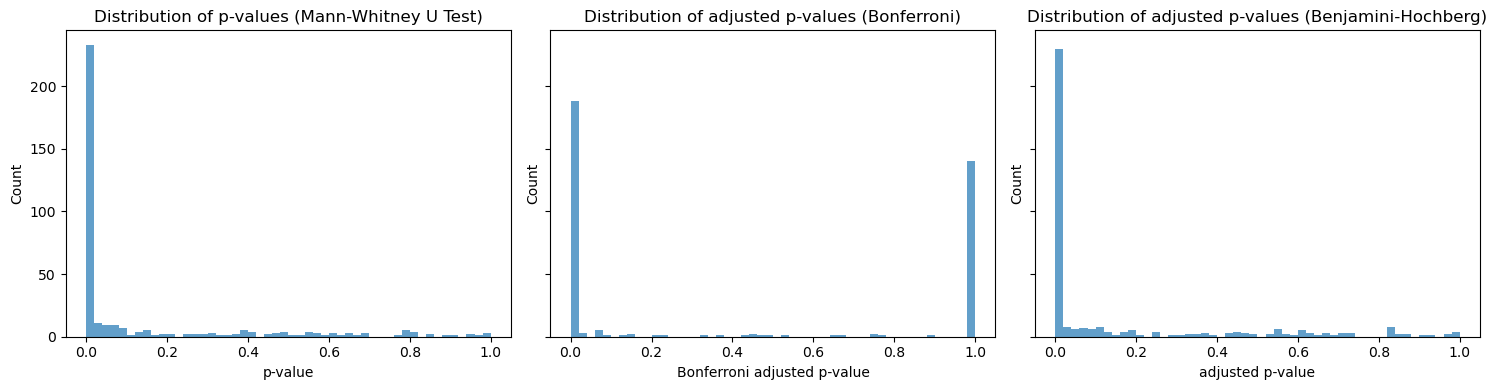

In [60]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

ax1.hist(mannwhitney_df['p_value'], bins=50, alpha=0.7)
ax1.set_xlabel('p-value')
ax1.set_ylabel('Count')
ax1.set_title('Distribution of p-values (Mann-Whitney U Test)')

ax2.hist(mannwhitney_df['p_adjusted_bonferroni'], bins=50, alpha=0.7)
ax2.set_xlabel('Bonferroni adjusted p-value')
ax2.set_ylabel('Count')
ax2.set_title('Distribution of adjusted p-values (Bonferroni)')

ax3.hist(mannwhitney_df['p_adjusted_bh'], bins=50, alpha=0.7)
ax3.set_xlabel('adjusted p-value')
ax3.set_ylabel('Count')
ax3.set_title('Distribution of adjusted p-values (Benjamini-Hochberg)')

plt.tight_layout()
plt.show()

Further analysis will use the Benjamini-Hochberg adjusted p-values. This method controls the false discovery rate (FDR) with a less strict and more balanced approach than the Bonferroni correction.

In [61]:
# Filter significant results (e.g., adjusted p-value < 0.05)
significant = mannwhitney_df[mannwhitney_df['p_adjusted_bh'] < 0.05].sort_values('p_adjusted_bh')

In [62]:
print(f"Total residue pairs tested: {len(mannwhitney_df)}")
print(f"Significant residue pairs (p_adj < 0.05): {len(significant)}")
print("\nTop 5 significant pairs:")
print(significant[['sele1', 'sele2', 'p_adjusted_bh']].head())

Total residue pairs tested: 356
Significant residue pairs (p_adj < 0.05): 242

Top 5 significant pairs:
     sele1 sele2  p_adjusted_bh
248  288_A   6_C            0.0
153  276_A   8_C            0.0
54   243_B   7_D            0.0
51   285_A  21_D            0.0
271  325_A   7_C            0.0


In [63]:
mannwhitney_df.shape

(356, 13)

In [64]:
significant.shape

(242, 13)

In [75]:
significant.sort_values('p_adjusted_bh', ascending=True).head(10)

,pair,sele1,sele2,sele1_resid,sele1_chain,sele2_resid,sele2_chain,u_statistic,p_value,n_cond1,n_cond2,p_adjusted_bonferroni,p_adjusted_bh
248,288_A-6_C,288_A,6_C,423,A,6,C,5.154946e+09,0.0,42772,211016,0.0,0.0
153,276_A-8_C,276_A,8_C,411,A,8,C,1.629924e+09,0.0,87054,43551,0.0,0.0
54,243_B-7_D,243_B,7_D,378,B,7,D,4.998470e+08,0.0,29903,40289,0.0,0.0
51,285_A-21_D,285_A,21_D,420,A,21,D,1.835949e+08,0.0,29782,16509,0.0,0.0
271,325_A-7_C,325_A,7_C,460,A,7,C,2.122890e+08,0.0,8770,37934,0.0,0.0
290,284_B-20_C,284_B,20_C,419,B,20,C,1.723640e+09,0.0,18733,146612,0.0,0.0
84,292_B-6_D,292_B,6_D,427,B,6,D,1.598680e+09,0.0,91895,43082,0.0,0.0
59,243_A-7_C,243_A,7_C,378,A,7,C,2.034850e+09,0.0,36907,93062,0.0,0.0
177,243_B-8_D,243_B,8_D,378,B,8,D,9.727484e+08,0.0,20601,76941,0.0,0.0
255,432_B-14_C,432_B,14_C,567,B,14,C,3.284495e+07,0.0,15887,6314,0.0,0.0


In [ ]:
def pivotdf_count_avg_sig_bh(df):
    pivot = df.pivot_table(values='p_adjusted_bh', 
                          index='sele2_resid', 
                          columns='sele1_resid', 
                          aggfunc='mean')
    return pivot

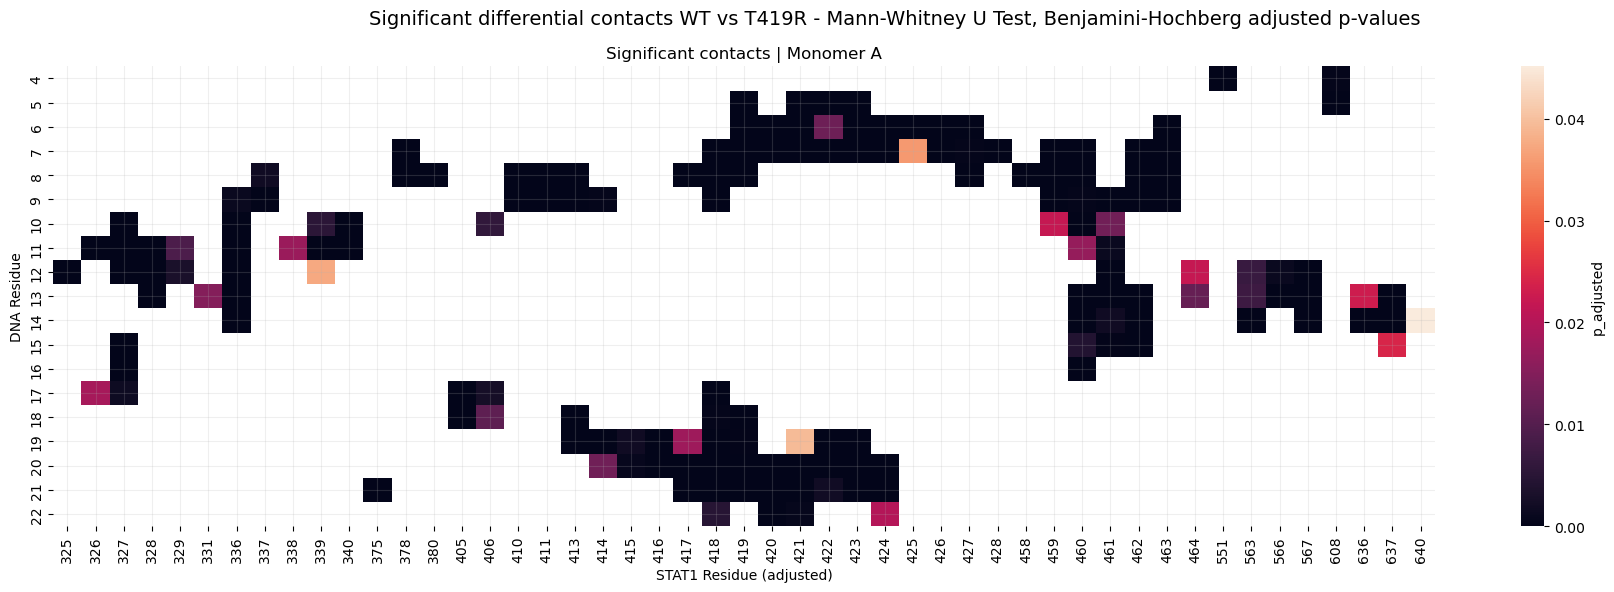

In [ ]:
significant_pivot = pivotdf_count_avg_sig_bh(significant)

plt.figure(figsize=(18, 6))

# Monomer A
sns.heatmap(significant_pivot, cmap='rocket', cbar_kws={'label': 'p_adjusted'})
plt.title('Significant contacts | Monomer A')
plt.xlabel('STAT1 Residue (adjusted)')
plt.ylabel('DNA Residue')
plt.grid(alpha=0.2)

plt.suptitle('Significant differential contacts WT vs T419R - Mann-Whitney U Test, Benjamini-Hochberg adjusted p-values', fontsize=14)

plt.tight_layout()
plt.show()

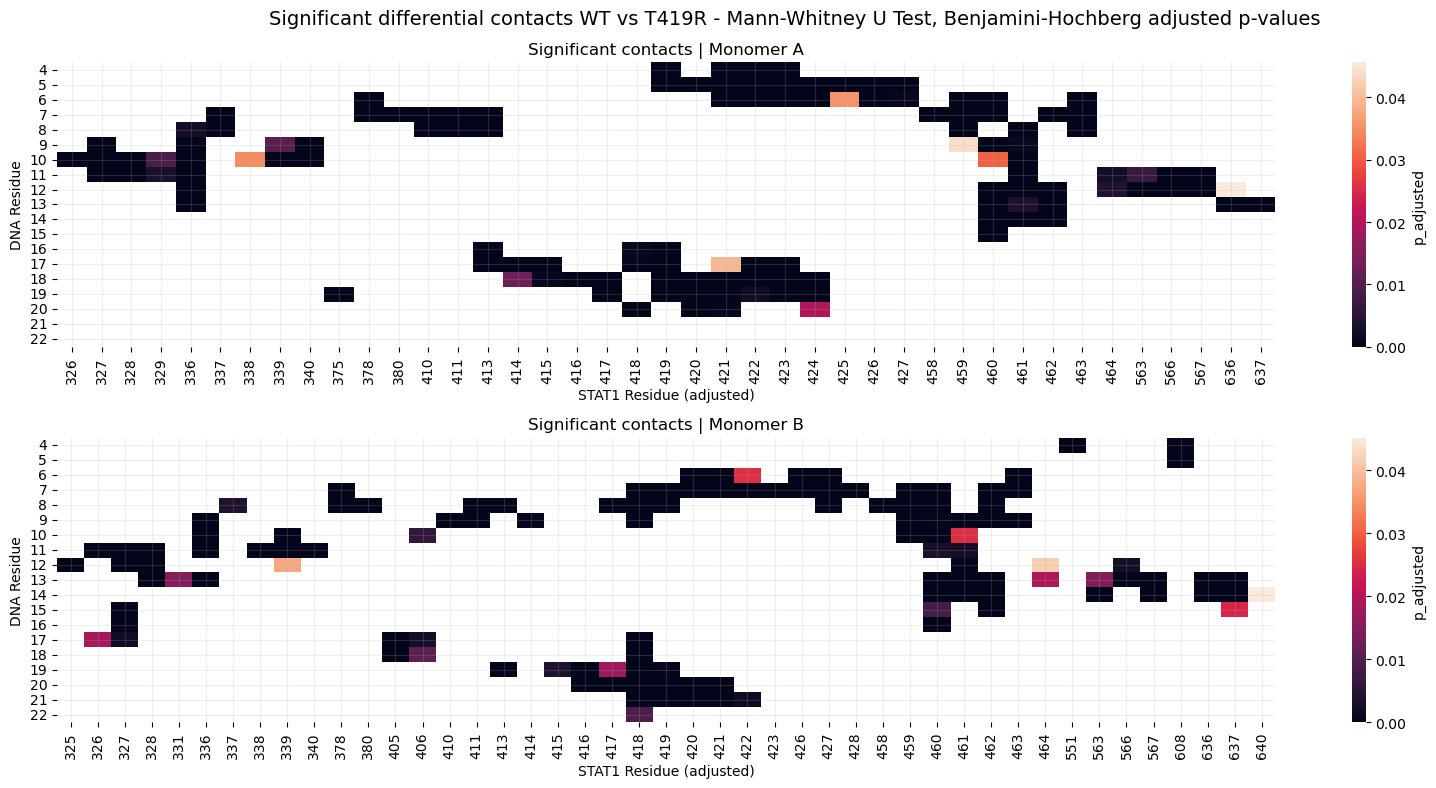

In [67]:
significant_monoA_pivot = pivotdf_count_avg_sig_bh(significant[significant['sele1_chain'] == 'A'])
significant_monoB_pivot = pivotdf_count_avg_sig_bh(significant[significant['sele1_chain'] == 'B'])


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), sharey=True)

# Monomer A
sns.heatmap(significant_monoA_pivot, cmap='rocket', ax=ax1, cbar_kws={'label': 'p_adjusted'})
ax1.set_title('Significant contacts | Monomer A')
ax1.set_xlabel('STAT1 Residue (adjusted)')
ax1.set_ylabel('DNA Residue')
ax1.grid(alpha=0.2)

# Monomer B
sns.heatmap(significant_monoB_pivot, cmap='rocket', ax=ax2, cbar_kws={'label': 'p_adjusted'})
ax2.set_title('Significant contacts | Monomer B')
ax2.set_xlabel('STAT1 Residue (adjusted)')
ax2.set_ylabel('DNA Residue')
ax2.grid(alpha=0.2)

plt.suptitle('Significant differential contacts WT vs T419R - Mann-Whitney U Test, Benjamini-Hochberg adjusted p-values', fontsize=14)

plt.tight_layout()
plt.show()

In [68]:
significant_monoA_dnaC_pivot = pivotdf_count_avg_sig_bh(significant[(significant['sele1_chain'] == 'A') & (significant['sele2_chain'] == 'C')])
significant_monoA_dnaD_pivot = pivotdf_count_avg_sig_bh(significant[(significant['sele1_chain'] == 'A') & (significant['sele2_chain'] == 'D')])
significant_monoB_dnaC_pivot = pivotdf_count_avg_sig_bh(significant[(significant['sele1_chain'] == 'B') & (significant['sele2_chain'] == 'C')])
significant_monoB_dnaD_pivot = pivotdf_count_avg_sig_bh(significant[(significant['sele1_chain'] == 'B') & (significant['sele2_chain'] == 'D')])

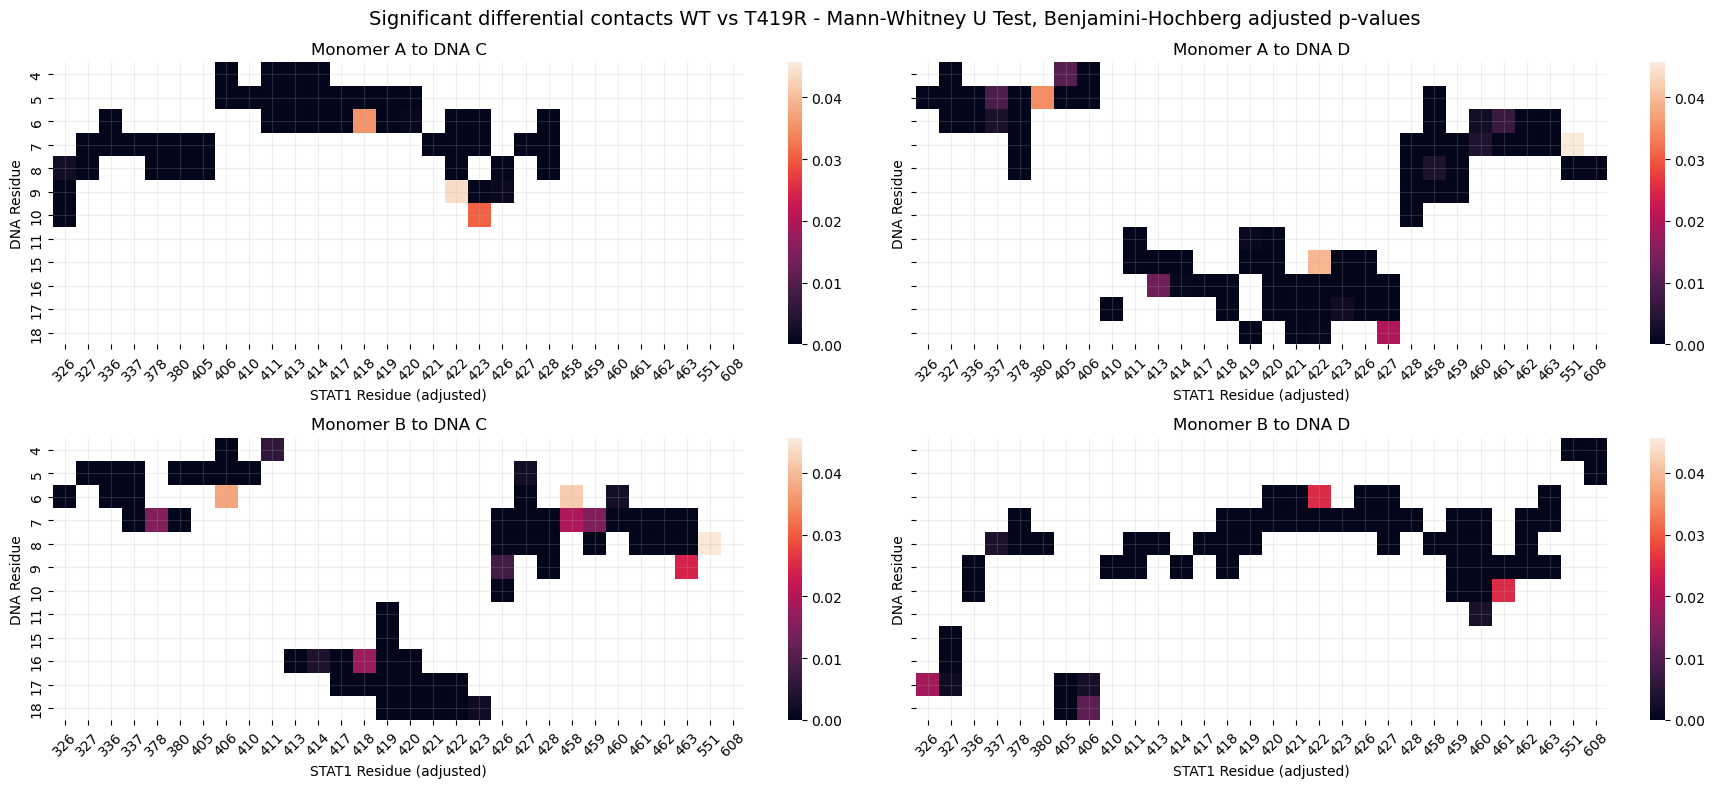

In [69]:
# Find global min and max
all_data = [
    significant_monoA_dnaC_pivot.values,
    significant_monoA_dnaD_pivot.values,
    significant_monoB_dnaC_pivot.values,
    significant_monoB_dnaD_pivot.values
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(18, 8), sharey=True, sharex=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (significant_monoA_dnaC_pivot, ax1, 'Monomer A to DNA C'),
    (significant_monoA_dnaD_pivot, ax2, 'Monomer A to DNA D'),
    (significant_monoB_dnaC_pivot, ax3, 'Monomer B to DNA C'),
    (significant_monoB_dnaD_pivot, ax4, 'Monomer B to DNA D')
]

for pivot_df, ax, title in plots:
    sns.heatmap(
        pivot_df, 
        cmap='rocket', 
        ax=ax, 
        cbar=True, 
        vmin=global_min, 
        vmax=global_max
    )
    ax.set_title(title)
    ax.set_xlabel('STAT1 Residue (adjusted)')
    ax.set_ylabel('DNA Residue')
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45, labelbottom=True)

plt.suptitle('Significant differential contacts WT vs T419R - Mann-Whitney U Test, Benjamini-Hochberg adjusted p-values', fontsize=14)
plt.tight_layout()
plt.show()

## Conclusion

Most of the contacts under the 5 Å distance threshold happen between the DNA-binding domain (DBD) of STAT1 and the dsDNA. Although extending the analysis to the complete available protein structure reveals some contacts beyond this domain, particularly with residue LYS 567 in the linker domain and LYS 636 in the SH2 domain, their count average is relatively low. Furthermore, the difference in count average between WT and T419R in these domains is close to 0.

In the DBD, the greatest difference in count average between WT and T419R is observed in residues ARG 418 and 419. The contacts seem to shift from 418 towards 419 in the mutation. As a result, in T419R the number of contacts with 419 increases and with 418 decreases, as compared to the WT count average. This result is consistent with the change from uncharged threonine to positively charged arginine. The positively charged ARG interacts with the negatively charged DNA backbone, resulting is closer contacts. 

This difference remains when filtering out closer contacts (< 3.5 Å), some of which have already being considered as hydrogen bonds in a separate analysis, provided the atoms within this distance also fulfill the electrochemical and angle properties required to form such a bond. Although the distance filter might exclude some contacts that are not considered as potential hydrogen bonds, it also proves that the differences in contact distribution between WT and T419R go beyond short distances.